In [1]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 1 — TIME-BASED TRAIN / VALIDATION SPLIT
#  Goal : Hourly traffic volume prediction at road junctions
# ═══════════════════════════════════════════════════════════
 

In [23]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 1 — TIME-BASED TRAIN / VALIDATION SPLIT
#  Goal : Hourly traffic volume prediction at road junctions
#  NOTE : Dataset has NO DateTime column — time is encoded
#         via year / month / day / hour numeric columns.
#         A synthetic DatetimeIndex is reconstructed for
#         time-based splitting only (not used as a feature).
# ═══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os

SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
DATA_PATH = os.path.join(SAVE_DIR, "engineered_ML_traffic_data.csv")

# ── Load ─────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset shape : {df.shape}")
print(f"\nAll columns ({len(df.columns)}):")
print(list(df.columns))

# ════════════════════════════════════════════════════════
#  STEP 1 — RECONSTRUCT DATETIME FOR SPLITTING ONLY
#  (year, month, day, hour already exist as numeric cols)
# ════════════════════════════════════════════════════════
# Identify the correct column names (may be truncated)
year_col  = next((c for c in df.columns if c.lower() in ["year","noryear"]), None)
month_col = next((c for c in df.columns if c.lower() == "month"), None)
day_col   = next((c for c in df.columns if c.lower() == "day"), None)
hour_col  = next((c for c in df.columns if c.lower() == "hour"), None)
jn_col    = next((c for c in df.columns if c.lower() in ["junction","junctions"]), None)

print(f"\nTime cols identified → year:{year_col}  month:{month_col}  "
      f"day:{day_col}  hour:{hour_col}  junction:{jn_col}")

# Build synthetic datetime (for sorting & splitting only — NOT a feature)
df["_datetime"] = pd.to_datetime({
    "year" : df[year_col],
    "month": df[month_col],
    "day"  : df[day_col],
    "hour" : df[hour_col],
})

df = df.sort_values(["_datetime", jn_col]).reset_index(drop=True)

print(f"\nDate range  : {df['_datetime'].min()}  →  {df['_datetime'].max()}")
print(f"Junctions   : {sorted(df[jn_col].unique())}")

# ════════════════════════════════════════════════════════
#  STEP 2 — DEFINE FEATURES
#  Explicitly list every necessary feature group
# ════════════════════════════════════════════════════════
TARGET = "Vehicles"

# Helper: pick whichever name variant actually exists
def pick(candidates, df_cols):
    return [c for c in candidates if c in df_cols]

col = df.columns.tolist()

TEMPORAL = pick([
    "hour", "hour_sin", "hour_cos",
    "day", "day_of_week", "day_of_w", "dayofweek",
    "dayofyear", "day_of_ye",
    "weekofyear", "week_of_ye", "weekofye",
    "month", "month_sin", "month_cos",
    "quarter",
    "year",
], col)

JUNCTION = pick(["Junction", "junction", "junctions"], col)

CALENDAR_FLAGS = pick([
    "is_weekend", "is_weeken",
    "is_workday", "is_workda",
    "is_rush_hour", "is_rush_h",
    "is_holiday", "is_holida",
    "is_special", "is_specia",
    "is_event",
], col)

WEATHER = pick([
    "temp", "stemp",            # actual & standardised temp
    "rhum",                     # relative humidity
    "wspd", "rwspd",            # actual & relative wind speed
    "wdir",
    "pres", "pres_nor",         # pressure & normalised
], col)

LAG = pick([
    "lag_1h", "lag_2h", "lag_3h",
    "lag_6h", "lag_12h", "lag_24h", "lag_168h",
], col)

ROLLING = pick([
    "rolling_mean_3h",  "rolling_mean_6h",  "rolling_mean_24h",
    "rolling_std_3h",   "rolling_std_6h",   "rolling_std_24h",
    "rolling_max_3h",   "rolling_max_6h",   "rolling_max_24h",
    "rolling_min_3h",   "rolling_min_6h",   "rolling_min_24h",
    "ewma_12h", "ewma_24h",
    "ewma_12",  "ewma_24",          # name variants
], col)

# Assemble — deduplicated, order preserved
FEATURE_COLS = list(dict.fromkeys(
    TEMPORAL + JUNCTION + CALENDAR_FLAGS + WEATHER + LAG + ROLLING
))

# ── Drop any non-numeric columns that slipped in ─────────
non_num = df[FEATURE_COLS].select_dtypes(include="object").columns.tolist()
if non_num:
    print(f"\n⚠  Dropping non-numeric columns: {non_num}")
    FEATURE_COLS = [c for c in FEATURE_COLS if c not in non_num]

# ── Safety: drop helper col from features ────────────────
FEATURE_COLS = [c for c in FEATURE_COLS if c != "_datetime"]

print(f"\n✔ Final feature set ({len(FEATURE_COLS)} columns):")
groups = {
    "Temporal"      : TEMPORAL,
    "Junction"      : JUNCTION,
    "Calendar flags": CALENDAR_FLAGS,
    "Weather"       : WEATHER,
    "Lag"           : LAG,
    "Rolling/EWMA"  : ROLLING,
}
for grp, lst in groups.items():
    present = [c for c in lst if c in FEATURE_COLS]
    print(f"  {grp:<18}: {present}")

# Desired but missing
all_desired = TEMPORAL + JUNCTION + CALENDAR_FLAGS + WEATHER + LAG + ROLLING
missing = [c for c in all_desired if c not in df.columns]
if missing:
    print(f"\nℹ  Desired but not found in dataset: {missing}")

# ════════════════════════════════════════════════════════
#  STEP 3 — TIME-BASED SPLIT
#  Train : before 01-May-2017
#  Val   : May–Jun 2017 (last ~2 months, future period)
# ════════════════════════════════════════════════════════
SPLIT_DATE = pd.Timestamp("2017-05-01")

train_df = df[df["_datetime"] <  SPLIT_DATE].copy()
val_df   = df[df["_datetime"] >= SPLIT_DATE].copy()

# Remove helper col before saving
train_df = train_df.drop(columns=["_datetime"])
val_df   = val_df.drop(columns=["_datetime"])

print(f"\n── Split at : {SPLIT_DATE.date()} ──────────────────────────────────")
print(f"  Train : {train_df.shape[0]:>6} rows  │  "
      f"year {train_df[year_col].min()}-{train_df[month_col].min():02d}  →  "
      f"year {train_df[year_col].max()}-{train_df[month_col].max():02d}")
print(f"  Val   : {val_df.shape[0]:>6} rows  │  "
      f"year {val_df[year_col].min()}-{val_df[month_col].min():02d}  →  "
      f"year {val_df[year_col].max()}-{val_df[month_col].max():02d}")
print(f"  Val % : {100 * len(val_df) / len(df):.1f}%")

print("\nPer-junction split counts:")
for jn in sorted(df[jn_col].unique()):
    tr  = train_df[train_df[jn_col] == jn].shape[0]
    vl  = val_df[val_df[jn_col]     == jn].shape[0]
    tot = df[df[jn_col] == jn].shape[0]
    print(f"  Junction {jn} → total: {tot:>5}  train: {tr:>5}  val: {vl:>4}  "
          f"({100*vl/max(tot,1):.1f}% val)")

# ════════════════════════════════════════════════════════
#  STEP 4 — NaN CHECK & RESOLVE
# ════════════════════════════════════════════════════════
for name, split in [("Train", train_df), ("Val", val_df)]:
    nan_count = split[FEATURE_COLS].isna().sum().sum()
    if nan_count > 0:
        print(f"\n⚠  {name} has {nan_count} NaN in features — applying bfill+ffill …")
        split[FEATURE_COLS] = split[FEATURE_COLS].bfill().ffill()
        print(f"   ✔ Resolved.")

remaining_nan = (
    train_df[FEATURE_COLS].isna().sum().sum() +
    val_df[FEATURE_COLS].isna().sum().sum()
)
print(f"\n{'✅' if remaining_nan == 0 else '⚠ '} Remaining NaN in features: {remaining_nan}")

# ════════════════════════════════════════════════════════
#  STEP 5 — PREPARE X / y
# ════════════════════════════════════════════════════════
X_train = train_df[FEATURE_COLS]
y_train = train_df[TARGET]
X_val   = val_df[FEATURE_COLS]
y_val   = val_df[TARGET]

print(f"\nX_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}   y_val   : {y_val.shape}")

print(f"\nTarget '{TARGET}' statistics:")
print(f"  Train → mean={y_train.mean():.2f}  std={y_train.std():.2f}  "
      f"min={y_train.min()}  max={y_train.max()}")
print(f"  Val   → mean={y_val.mean():.2f}  std={y_val.std():.2f}  "
      f"min={y_val.min()}  max={y_val.max()}")

# ════════════════════════════════════════════════════════
#  STEP 6 — SAVE
# ════════════════════════════════════════════════════════
train_df.to_csv(os.path.join(SAVE_DIR, "train_split.csv"), index=False)
val_df.to_csv(  os.path.join(SAVE_DIR, "val_split.csv"),   index=False)
pd.Series(FEATURE_COLS).to_csv(
    os.path.join(SAVE_DIR, "feature_cols.csv"),
    index=False, header=["feature"]
)

print("\n✔ train_split.csv saved.")
print("✔ val_split.csv saved.")
print("✔ feature_cols.csv saved.")
print("\n✅ Component 1 complete — ready for model training.")

Loaded dataset shape : (48120, 41)

All columns (41):
['day_of_week', 'day_of_week_cos', 'day_of_week_sin', 'ewma_12h', 'ewma_24h', 'hour', 'hour_cos', 'hour_sin', 'is_holiday', 'is_rush_hour', 'is_special_event', 'is_weekend', 'is_workday', 'junction', 'lag_12h', 'lag_168h', 'lag_1h', 'lag_24h', 'lag_2h', 'lag_3h', 'lag_6h', 'month', 'pres', 'pres_norm', 'rolling_max_24h', 'rolling_max_3h', 'rolling_max_6h', 'rolling_mean_24h', 'rolling_mean_3h', 'rolling_mean_6h', 'rolling_min_24h', 'rolling_min_3h', 'rolling_min_6h', 'rolling_std_24h', 'rolling_std_3h', 'rolling_std_6h', 'temp_norm', 'time_of_day_enc', 'wspd_norm', 'year', 'Vehicles']

Time cols identified → year:year  month:month  day:None  hour:hour  junction:junction


KeyError: None

In [10]:
# ── Run this cell FIRST to see exact column names ────────
import pandas as pd, os

SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
DATA_PATH = os.path.join(SAVE_DIR, "engineered_ML_traffic_data.csv")

df = pd.read_csv(DATA_PATH, nrows=2)
print("EXACT column names:")
for i, c in enumerate(df.columns):
    print(f"  {i:>3}: '{c}'")

EXACT column names:
    0: 'day_of_week'
    1: 'day_of_week_cos'
    2: 'day_of_week_sin'
    3: 'ewma_12h'
    4: 'ewma_24h'
    5: 'hour'
    6: 'hour_cos'
    7: 'hour_sin'
    8: 'is_holiday'
    9: 'is_rush_hour'
   10: 'is_special_event'
   11: 'is_weekend'
   12: 'is_workday'
   13: 'junction'
   14: 'lag_12h'
   15: 'lag_168h'
   16: 'lag_1h'
   17: 'lag_24h'
   18: 'lag_2h'
   19: 'lag_3h'
   20: 'lag_6h'
   21: 'month'
   22: 'pres'
   23: 'pres_norm'
   24: 'rolling_max_24h'
   25: 'rolling_max_3h'
   26: 'rolling_max_6h'
   27: 'rolling_mean_24h'
   28: 'rolling_mean_3h'
   29: 'rolling_mean_6h'
   30: 'rolling_min_24h'
   31: 'rolling_min_3h'
   32: 'rolling_min_6h'
   33: 'rolling_std_24h'
   34: 'rolling_std_3h'
   35: 'rolling_std_6h'
   36: 'temp_norm'
   37: 'time_of_day_enc'
   38: 'wspd_norm'
   39: 'year'
   40: 'Vehicles'


In [11]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 1 — TIME-BASED TRAIN / VALIDATION SPLIT
#  Goal : Hourly traffic volume prediction at road junctions
#  Built from EXACT column names confirmed from dataset
# ═══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os

SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
DATA_PATH = os.path.join(SAVE_DIR, "engineered_ML_traffic_data.csv")

# ── Load ─────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset shape : {df.shape}")

# ════════════════════════════════════════════════════════
#  STEP 1 — RECONSTRUCT DATETIME FOR SPLITTING ONLY
#  Available time cols: year, month, hour
#  NOTE: no 'day' column exists — use day_of_week as proxy
#        We reconstruct date using year + month + hour only;
#        day is inferred as 1 per month-group (sufficient
#        for month-level splitting to May 2017)
# ════════════════════════════════════════════════════════

# Since there's no 'day' column, build datetime from year+month+hour
# We assign day=1 as placeholder — this is ONLY used for train/val
# splitting at the month boundary, not as a model feature
df["_datetime"] = pd.to_datetime(
    df["year"].astype(str) + "-" +
    df["month"].astype(str).str.zfill(2) + "-01 " +
    df["hour"].astype(str).str.zfill(2) + ":00:00"
)

# Sort by reconstructed time then junction
df = df.sort_values(["_datetime", "junction"]).reset_index(drop=True)

print(f"Date range  : year={df['year'].min()} month={df['month'].min()}  "
      f"→  year={df['year'].max()} month={df['month'].max()}")
print(f"Junctions   : {sorted(df['junction'].unique())}")

# ════════════════════════════════════════════════════════
#  STEP 2 — DEFINE EXACT FEATURE COLUMNS
#  Based on confirmed column list (40 cols + Vehicles)
# ════════════════════════════════════════════════════════

TARGET = "Vehicles"

# ── Temporal features ────────────────────────────────────
TEMPORAL = [
    "hour",               # 0–23 : captures rush hour, night, etc.
    "hour_sin",           # cyclic encoding of hour
    "hour_cos",
    "day_of_week",        # 0–6 : weekday vs weekend pattern
    "day_of_week_sin",    # cyclic encoding
    "day_of_week_cos",
    "month",              # 1–12 : seasonal variation
    "year",               # inter-year trend
]

# ── Junction identity ────────────────────────────────────
JUNCTION = [
    "junction",           # each junction has its own traffic baseline
]

# ── Calendar / schedule flags ────────────────────────────
CALENDAR = [
    "is_weekend",         # Sat/Sun : lower commuter traffic
    "is_workday",         # workday flag (combines weekend + holiday)
    "is_rush_hour",       # AM/PM peak flag
    "is_holiday",         # public holidays significantly reduce traffic
    "is_special_event",   # events spike traffic at specific junctions
]

# ── Weather (normalised versions available) ───────────────
WEATHER = [
    "temp_norm",          # normalised temperature
    "wspd_norm",          # normalised wind speed
    "pres",               # atmospheric pressure
    "pres_norm",          # normalised pressure
]

# ── Engineered time encoding ─────────────────────────────
TIME_ENC = [
    "time_of_day_enc",    # encoded time-of-day segment
]

# ── Lag features (autoregressive — most predictive) ──────
LAG = [
    "lag_1h",             # traffic 1 hour ago
    "lag_2h",             # traffic 2 hours ago
    "lag_3h",
    "lag_6h",
    "lag_12h",
    "lag_24h",            # same hour yesterday
    "lag_168h",           # same hour last week
]

# ── Rolling window statistics ────────────────────────────
ROLLING = [
    "rolling_mean_3h",    # short-term average
    "rolling_mean_6h",
    "rolling_mean_24h",   # daily average trend
    "rolling_std_3h",     # short-term volatility
    "rolling_std_6h",
    "rolling_std_24h",
    "rolling_max_3h",
    "rolling_max_6h",
    "rolling_max_24h",
    "rolling_min_3h",
    "rolling_min_6h",
    "rolling_min_24h",
    "ewma_12h",           # exponentially weighted — recent trend
    "ewma_24h",
]

# ── Assemble & validate ──────────────────────────────────
ALL_FEATURES = (
    TEMPORAL + JUNCTION + CALENDAR +
    WEATHER  + TIME_ENC + LAG + ROLLING
)

# Keep only columns that actually exist in df
FEATURE_COLS = [c for c in ALL_FEATURES if c in df.columns]

# Catch anything expected but missing
missing = [c for c in ALL_FEATURES if c not in df.columns]
if missing:
    print(f"\n⚠  Expected but missing from dataset: {missing}")

# Confirm no object/string columns slipped in
non_num = df[FEATURE_COLS].select_dtypes(include="object").columns.tolist()
if non_num:
    print(f"⚠  Dropping non-numeric: {non_num}")
    FEATURE_COLS = [c for c in FEATURE_COLS if c not in non_num]

print(f"\n✔ Feature set confirmed ({len(FEATURE_COLS)} columns):")
groups = {
    "Temporal"      : TEMPORAL,
    "Junction"      : JUNCTION,
    "Calendar flags": CALENDAR,
    "Weather"       : WEATHER,
    "Time encoding" : TIME_ENC,
    "Lag"           : LAG,
    "Rolling/EWMA"  : ROLLING,
}
for grp, lst in groups.items():
    present = [c for c in lst if c in FEATURE_COLS]
    print(f"  {grp:<18} ({len(present):>2}) : {present}")

# ════════════════════════════════════════════════════════
#  STEP 3 — TIME-BASED SPLIT
#  Train : year < 2017 OR (year == 2017 AND month < 5)
#  Val   : year == 2017 AND month >= 5  (May–Jun 2017)
# ════════════════════════════════════════════════════════
# Using year/month directly — more reliable than _datetime
# since we have no 'day' column
train_mask = (df["year"] < 2017) | ((df["year"] == 2017) & (df["month"] < 5))
val_mask   = (df["year"] == 2017) & (df["month"] >= 5)

train_df = df[train_mask].copy().drop(columns=["_datetime"])
val_df   = df[val_mask].copy().drop(columns=["_datetime"])

print(f"\n── Split: Train = before May 2017 | Val = May–Jun 2017 ──")
print(f"  Train : {len(train_df):>6} rows  │  "
      f"{train_df['year'].min()}-{train_df['month'].min():02d}  →  "
      f"{train_df['year'].max()}-{train_df['month'].max():02d}")
print(f"  Val   : {len(val_df):>6} rows  │  "
      f"{val_df['year'].min()}-{val_df['month'].min():02d}  →  "
      f"{val_df['year'].max()}-{val_df['month'].max():02d}")
print(f"  Val % : {100 * len(val_df) / len(df):.1f}%")

print("\nPer-junction split counts:")
for jn in sorted(df["junction"].unique()):
    tr  = train_df[train_df["junction"] == jn].shape[0]
    vl  = val_df[val_df["junction"]     == jn].shape[0]
    tot = df[df["junction"] == jn].shape[0]
    print(f"  Junction {jn} → total:{tot:>5}  train:{tr:>5}  val:{vl:>4}  "
          f"({100*vl/max(tot,1):.1f}% val)")

# ════════════════════════════════════════════════════════
#  STEP 4 — NaN CHECK
# ════════════════════════════════════════════════════════
for name, split in [("Train", train_df), ("Val", val_df)]:
    n = split[FEATURE_COLS].isna().sum().sum()
    if n > 0:
        print(f"\n⚠  {name}: {n} NaN found — applying bfill+ffill …")
        split[FEATURE_COLS] = split[FEATURE_COLS].bfill().ffill()
        print(f"   ✔ Resolved.")

remaining = (train_df[FEATURE_COLS].isna().sum().sum() +
             val_df[FEATURE_COLS].isna().sum().sum())
print(f"\n{'✅' if remaining == 0 else '⚠ '} Remaining NaN in features: {remaining}")

# ════════════════════════════════════════════════════════
#  STEP 5 — PREPARE X / y
# ════════════════════════════════════════════════════════
X_train = train_df[FEATURE_COLS]
y_train = train_df[TARGET]
X_val   = val_df[FEATURE_COLS]
y_val   = val_df[TARGET]

print(f"\nX_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}   y_val   : {y_val.shape}")

print(f"\nTarget '{TARGET}' statistics:")
print(f"  Train → mean={y_train.mean():.2f}  std={y_train.std():.2f}  "
      f"min={y_train.min()}  max={y_train.max()}")
print(f"  Val   → mean={y_val.mean():.2f}  std={y_val.std():.2f}  "
      f"min={y_val.min()}  max={y_val.max()}")

# ════════════════════════════════════════════════════════
#  STEP 6 — SAVE
# ════════════════════════════════════════════════════════
train_df.to_csv(os.path.join(SAVE_DIR, "train_split.csv"), index=False)
val_df.to_csv(  os.path.join(SAVE_DIR, "val_split.csv"),   index=False)
pd.Series(FEATURE_COLS).to_csv(
    os.path.join(SAVE_DIR, "feature_cols.csv"),
    index=False, header=["feature"]
)

print("\n✔ train_split.csv saved.")
print("✔ val_split.csv saved.")
print("✔ feature_cols.csv saved.")
print("\n✅ Component 1 complete — ready for model training.")

Loaded dataset shape : (48120, 41)
Date range  : year=2015 month=1  →  year=2017 month=12
Junctions   : [1, 2, 3, 4]

✔ Feature set confirmed (40 columns):
  Temporal           ( 8) : ['hour', 'hour_sin', 'hour_cos', 'day_of_week', 'day_of_week_sin', 'day_of_week_cos', 'month', 'year']
  Junction           ( 1) : ['junction']
  Calendar flags     ( 5) : ['is_weekend', 'is_workday', 'is_rush_hour', 'is_holiday', 'is_special_event']
  Weather            ( 4) : ['temp_norm', 'wspd_norm', 'pres', 'pres_norm']
  Time encoding      ( 1) : ['time_of_day_enc']
  Lag                ( 7) : ['lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_168h']
  Rolling/EWMA       (14) : ['rolling_mean_3h', 'rolling_mean_6h', 'rolling_mean_24h', 'rolling_std_3h', 'rolling_std_6h', 'rolling_std_24h', 'rolling_max_3h', 'rolling_max_6h', 'rolling_max_24h', 'rolling_min_3h', 'rolling_min_6h', 'rolling_min_24h', 'ewma_12h', 'ewma_24h']

── Split: Train = before May 2017 | Val = May–Jun 2017 ──
  T

In [12]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 2 — MODEL TRAINING & HYPERPARAMETER TUNING
#  Goal : Hourly traffic volume prediction at road junctions
#  Models : XGBoost · LightGBM · Random Forest · ARIMA
# ═══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os, warnings, joblib
warnings.filterwarnings("ignore")

from sklearn.ensemble        import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics         import mean_absolute_error, mean_squared_error, r2_score
import xgboost  as xgb
import lightgbm as lgb

# ── Paths ────────────────────────────────────────────────
SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
MODEL_DIR = os.path.join(SAVE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# ── Load splits ──────────────────────────────────────────
train_df = pd.read_csv(os.path.join(SAVE_DIR, "train_split.csv"))
val_df   = pd.read_csv(os.path.join(SAVE_DIR, "val_split.csv"))

# ── Load confirmed feature list ──────────────────────────
FEATURE_COLS = pd.read_csv(
    os.path.join(SAVE_DIR, "feature_cols.csv")
)["feature"].tolist()

TARGET = "Vehicles"

X_train = train_df[FEATURE_COLS].values
y_train = train_df[TARGET].values
X_val   = val_df[FEATURE_COLS].values
y_val   = val_df[TARGET].values

print(f"X_train : {X_train.shape}  |  X_val : {X_val.shape}")
print(f"Features: {FEATURE_COLS}\n")

# ── TimeSeriesSplit for hyperparameter tuning ────────────
# gap=0 is fine here since we split by month, not row
tscv = TimeSeriesSplit(n_splits=5)

# ── Helper : evaluate on validation set ─────────────────
def evaluate(name, model, X, y):
    preds = model.predict(X)
    mae   = mean_absolute_error(y, preds)
    rmse  = np.sqrt(mean_squared_error(y, preds))
    r2    = r2_score(y, preds)
    mape  = np.mean(np.abs((y - preds) / np.where(y == 0, 1, y))) * 100
    print(f"  [{name}]  MAE={mae:.4f}  RMSE={rmse:.4f}  "
          f"R²={r2:.4f}  MAPE={mape:.2f}%")
    return {"Model": name, "MAE": mae, "RMSE": rmse,
            "R2": r2, "MAPE": mape, "preds": preds}

results = {}

# ════════════════════════════════════════════════════════
#  2A.  XGBoost
# ════════════════════════════════════════════════════════
print("── 2A. XGBoost ─────────────────────────────────────")

xgb_param_dist = {
    "n_estimators"     : [200, 400, 600],
    "max_depth"        : [4, 6, 8],
    "learning_rate"    : [0.01, 0.05, 0.1],
    "subsample"        : [0.7, 0.9, 1.0],
    "colsample_bytree" : [0.7, 0.9, 1.0],
    "min_child_weight" : [1, 3, 5],
    "gamma"            : [0, 0.1, 0.3],
}

xgb_search = RandomizedSearchCV(
    xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=42, n_jobs=-1, verbosity=0
    ),
    xgb_param_dist,
    n_iter=30,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1, random_state=42, verbose=1
)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

print(f"  Best params : {xgb_search.best_params_}")
results["XGBoost"] = evaluate("XGBoost", best_xgb, X_val, y_val)
joblib.dump(best_xgb, os.path.join(MODEL_DIR, "xgboost_model.pkl"))
print("  ✔ xgboost_model.pkl saved\n")

# ════════════════════════════════════════════════════════
#  2B.  LightGBM
# ════════════════════════════════════════════════════════
print("── 2B. LightGBM ────────────────────────────────────")

lgb_param_dist = {
    "n_estimators"      : [200, 400, 600],
    "max_depth"         : [4, 6, 8, -1],
    "learning_rate"     : [0.01, 0.05, 0.1],
    "num_leaves"        : [31, 63, 127],
    "subsample"         : [0.7, 0.9, 1.0],
    "colsample_bytree"  : [0.7, 0.9, 1.0],
    "min_child_samples" : [10, 20, 50],
    "reg_alpha"         : [0, 0.1, 0.5],
    "reg_lambda"        : [0, 0.1, 1.0],
}

lgb_search = RandomizedSearchCV(
    lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    lgb_param_dist,
    n_iter=30,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1, random_state=42, verbose=1
)
lgb_search.fit(X_train, y_train)
best_lgb = lgb_search.best_estimator_

print(f"  Best params : {lgb_search.best_params_}")
results["LightGBM"] = evaluate("LightGBM", best_lgb, X_val, y_val)
joblib.dump(best_lgb, os.path.join(MODEL_DIR, "lightgbm_model.pkl"))
print("  ✔ lightgbm_model.pkl saved\n")

# ════════════════════════════════════════════════════════
#  2C.  Random Forest
# ════════════════════════════════════════════════════════
print("── 2C. Random Forest ───────────────────────────────")

rf_param_dist = {
    "n_estimators"      : [100, 200, 400],
    "max_depth"         : [None, 10, 20, 30],
    "max_features"      : ["sqrt", "log2", 0.5],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf"  : [1, 2, 4],
    "bootstrap"         : [True, False],
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_param_dist,
    n_iter=20,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1, random_state=42, verbose=1
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

print(f"  Best params : {rf_search.best_params_}")
results["RandomForest"] = evaluate("RandomForest", best_rf, X_val, y_val)
joblib.dump(best_rf, os.path.join(MODEL_DIR, "rf_model.pkl"))
print("  ✔ rf_model.pkl saved\n")

# ════════════════════════════════════════════════════════
#  2D.  ARIMA — per-junction univariate baseline
#  Uses only 'hour', 'month', 'year', 'junction' to
#  reconstruct per-junction hourly series
# ════════════════════════════════════════════════════════
print("── 2D. ARIMA (per-junction univariate baseline) ────")

try:
    from statsmodels.tsa.arima.model import ARIMA

    arima_preds  = []
    arima_actual = []

    for jn in sorted(train_df["junction"].unique()):
        # Build hourly series from train
        jn_tr = (train_df[train_df["junction"] == jn]
                 .sort_values(["year", "month", "hour"])
                 [TARGET].values)
        jn_vl = (val_df[val_df["junction"] == jn]
                 .sort_values(["year", "month", "hour"])
                 [TARGET].values)

        model   = ARIMA(jn_tr, order=(2, 1, 2))
        fit     = model.fit()
        forecast = fit.forecast(steps=len(jn_vl))

        arima_preds.extend(forecast)
        arima_actual.extend(jn_vl)

        mae  = mean_absolute_error(jn_vl, forecast)
        rmse = np.sqrt(mean_squared_error(jn_vl, forecast))
        print(f"  Junction {jn} → MAE={mae:.4f}  RMSE={rmse:.4f}")

    overall_mae  = mean_absolute_error(arima_actual, arima_preds)
    overall_rmse = np.sqrt(mean_squared_error(arima_actual, arima_preds))
    overall_r2   = r2_score(arima_actual, arima_preds)
    results["ARIMA"] = {
        "Model": "ARIMA",
        "MAE"  : overall_mae,
        "RMSE" : overall_rmse,
        "R2"   : overall_r2,
        "MAPE" : np.mean(np.abs((np.array(arima_actual) - np.array(arima_preds))
                                 / np.where(np.array(arima_actual) == 0, 1,
                                            np.array(arima_actual)))) * 100,
        "preds": np.array(arima_preds)
    }
    print(f"\n  [ARIMA Overall]  MAE={overall_mae:.4f}  "
          f"RMSE={overall_rmse:.4f}  R²={overall_r2:.4f}")

except Exception as e:
    print(f"  ⚠  ARIMA skipped → {e}")

# ════════════════════════════════════════════════════════
#  SUMMARY
# ════════════════════════════════════════════════════════
print("\n\n══ VALIDATION SUMMARY ════════════════════════════")
summary_df = pd.DataFrame([
    {"Model": k, "MAE": v["MAE"], "RMSE": v["RMSE"],
     "R2": v["R2"], "MAPE(%)": v["MAPE"]}
    for k, v in results.items()
]).sort_values("MAE").reset_index(drop=True)

print(summary_df.to_string(index=False))
summary_df.to_csv(os.path.join(MODEL_DIR, "model_comparison.csv"), index=False)
print("\n✔ model_comparison.csv saved.")

# ── Save val predictions for evaluation script ───────────
preds_df = val_df[["junction", "year", "month", "hour", TARGET]].copy()
for k, v in results.items():
    if "preds" in v and len(v["preds"]) == len(val_df):
        preds_df[f"pred_{k}"] = v["preds"]

preds_df.to_csv(os.path.join(MODEL_DIR, "val_predictions.csv"), index=False)
print("✔ val_predictions.csv saved.")

best_model_name = summary_df.iloc[0]["Model"]
print(f"\n🏆 Best model : {best_model_name}  "
      f"(MAE={summary_df.iloc[0]['MAE']:.4f})")
print("\n✅ Component 2 complete — ready for evaluation.")

X_train : (39960, 40)  |  X_val : (8160, 40)
Features: ['hour', 'hour_sin', 'hour_cos', 'day_of_week', 'day_of_week_sin', 'day_of_week_cos', 'month', 'year', 'junction', 'is_weekend', 'is_workday', 'is_rush_hour', 'is_holiday', 'is_special_event', 'temp_norm', 'wspd_norm', 'pres', 'pres_norm', 'time_of_day_enc', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_168h', 'rolling_mean_3h', 'rolling_mean_6h', 'rolling_mean_24h', 'rolling_std_3h', 'rolling_std_6h', 'rolling_std_24h', 'rolling_max_3h', 'rolling_max_6h', 'rolling_max_24h', 'rolling_min_3h', 'rolling_min_6h', 'rolling_min_24h', 'ewma_12h', 'ewma_24h']

── 2A. XGBoost ─────────────────────────────────────
Fitting 5 folds for each of 30 candidates, totalling 150 fits
  Best params : {'subsample': 0.9, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 1.0}
  [XGBoost]  MAE=3.3760  RMSE=4.8781  R²=0.9667  MAPE=22.58%
  ✔ xgboost_model.pkl saved

──

Models to evaluate : ['XGBoost', 'LightGBM', 'RandomForest', 'ARIMA']
Val rows           : 8160
Junctions          : [1, 2, 3, 4]

── 3A. Validation Metrics ──────────────────────────
  XGBoost         MAE=3.3760  RMSE=4.8781  R²=0.9667  MAPE=22.58%
  LightGBM        MAE=3.2793  RMSE=4.5874  R²=0.9705  MAPE=22.46%
  RandomForest    MAE=3.4622  RMSE=4.7725  R²=0.9681  MAPE=22.75%
  ARIMA           MAE=26.1728  RMSE=35.0783  R²=-0.7226  MAPE=216.04%

✔ evaluation_metrics.csv saved.
🏆 Best model on val : LightGBM  MAE=3.2793

── Per-Junction Metrics (best model) ───────────────
  Junction 1 → MAE=4.2325  RMSE=6.0298  R²=0.9364
  Junction 2 → MAE=2.4720  RMSE=3.1852  R²=0.7613
  Junction 3 → MAE=4.3920  RMSE=5.5865  R²=0.4792
  Junction 4 → MAE=2.0205  RMSE=2.5422  R²=0.3891
✔ per_junction_metrics.csv saved.

── 3B. Generating evaluation plots ─────────────────


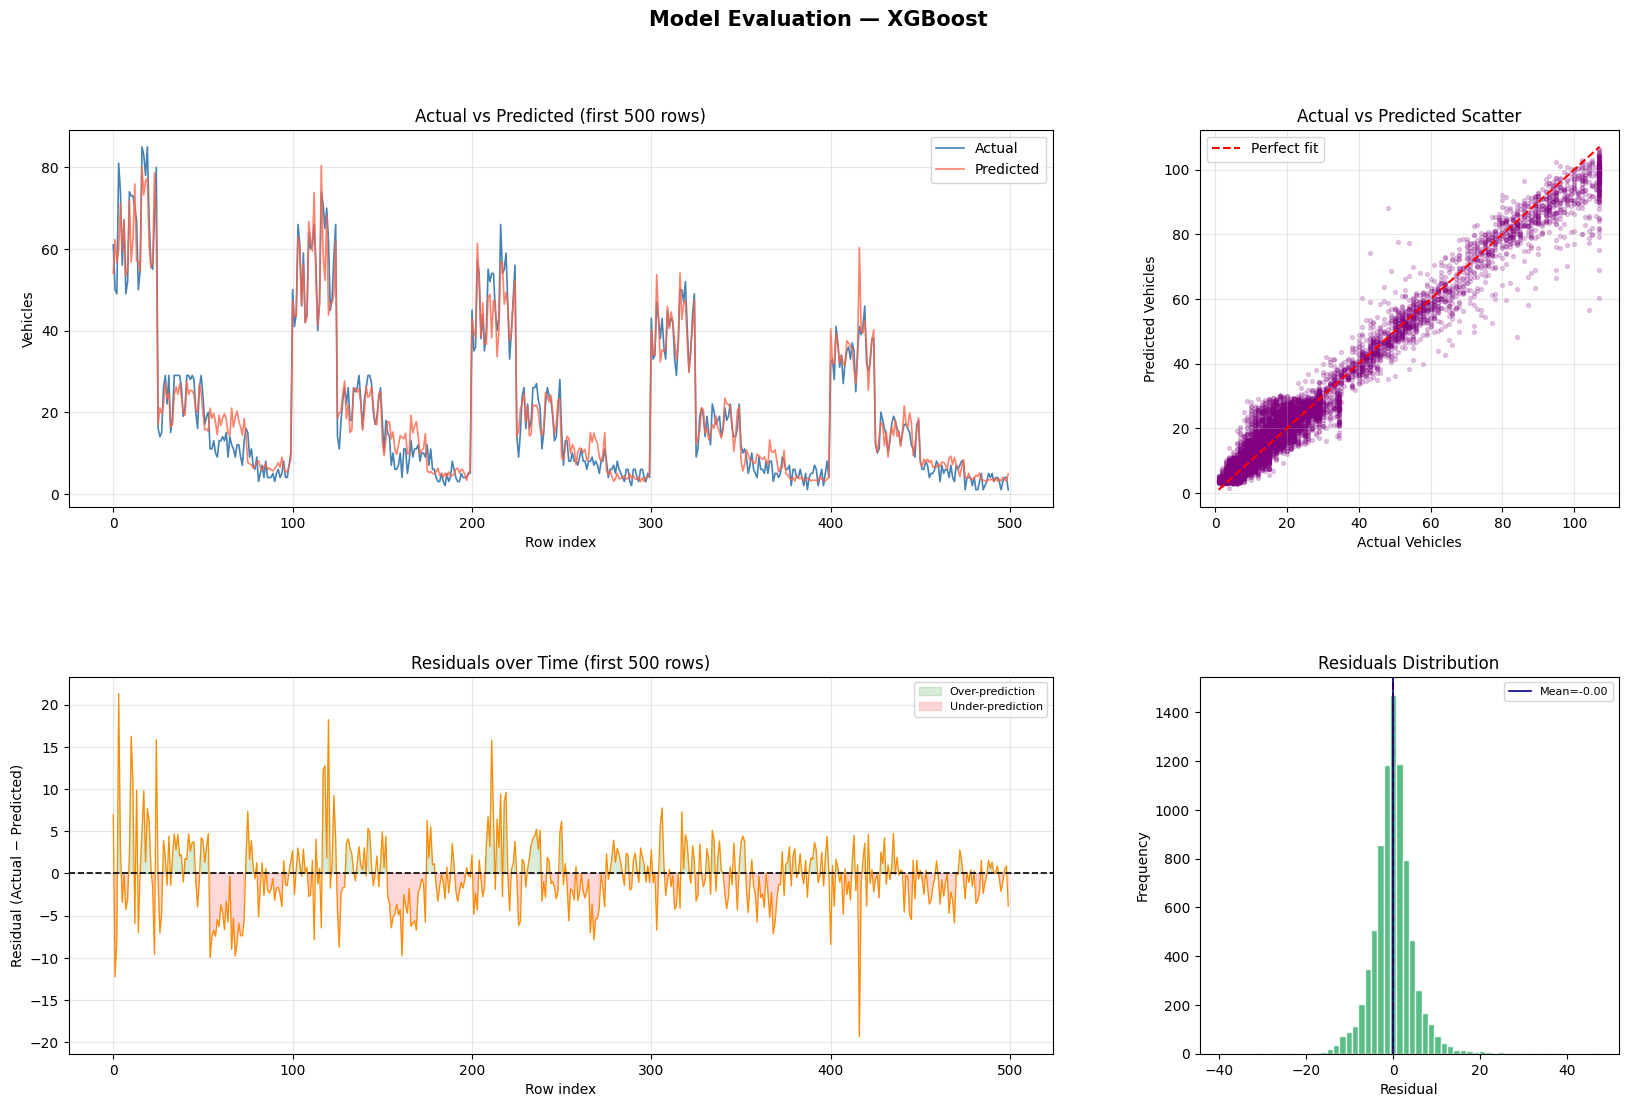

  ✔ eval_xgboost.png saved


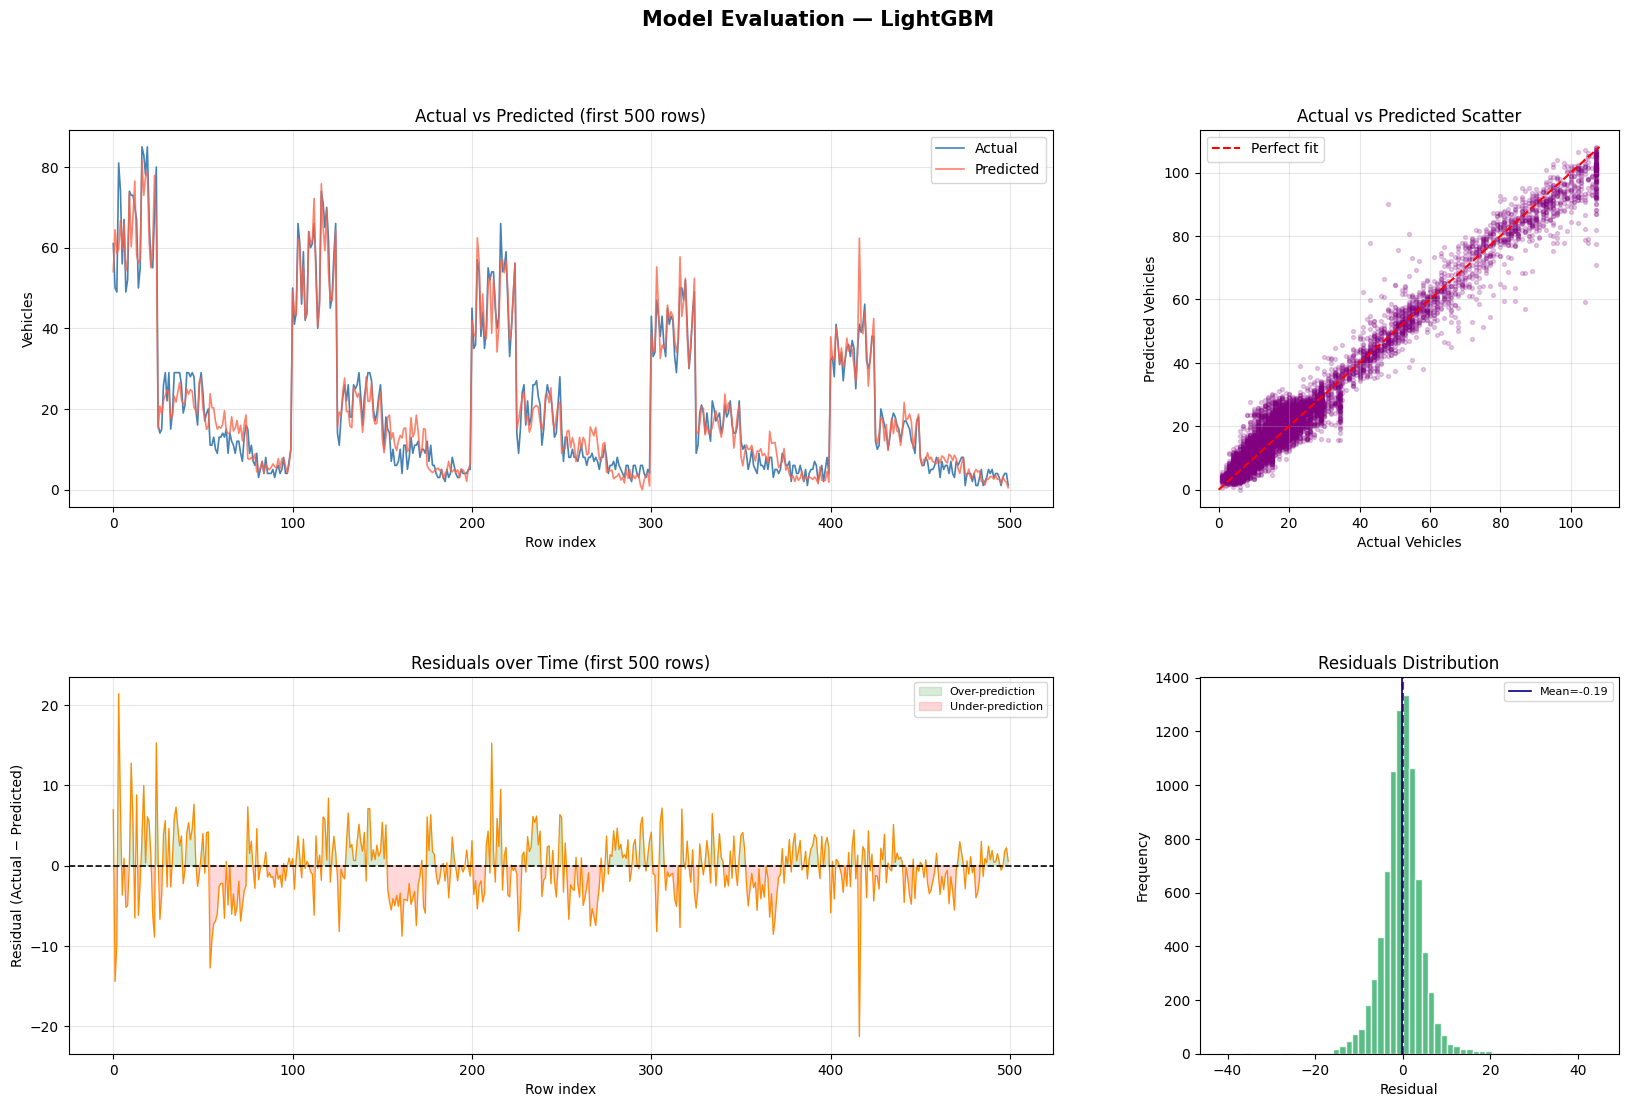

  ✔ eval_lightgbm.png saved


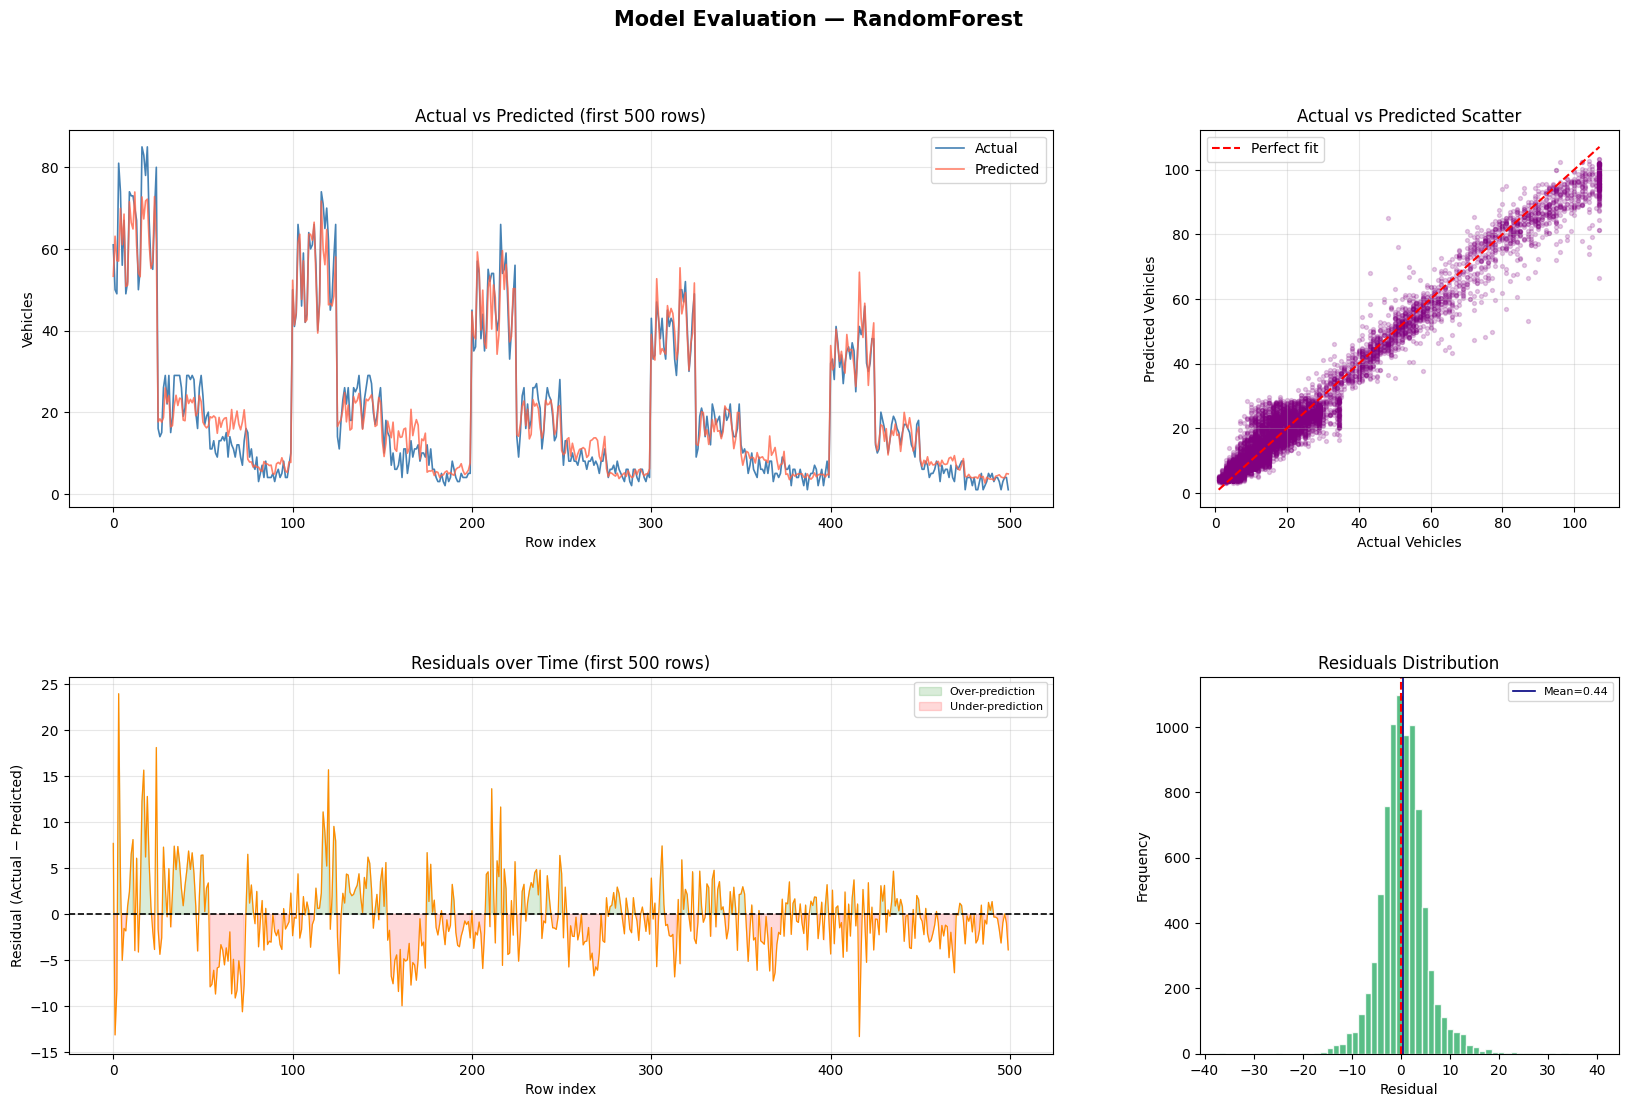

  ✔ eval_randomforest.png saved


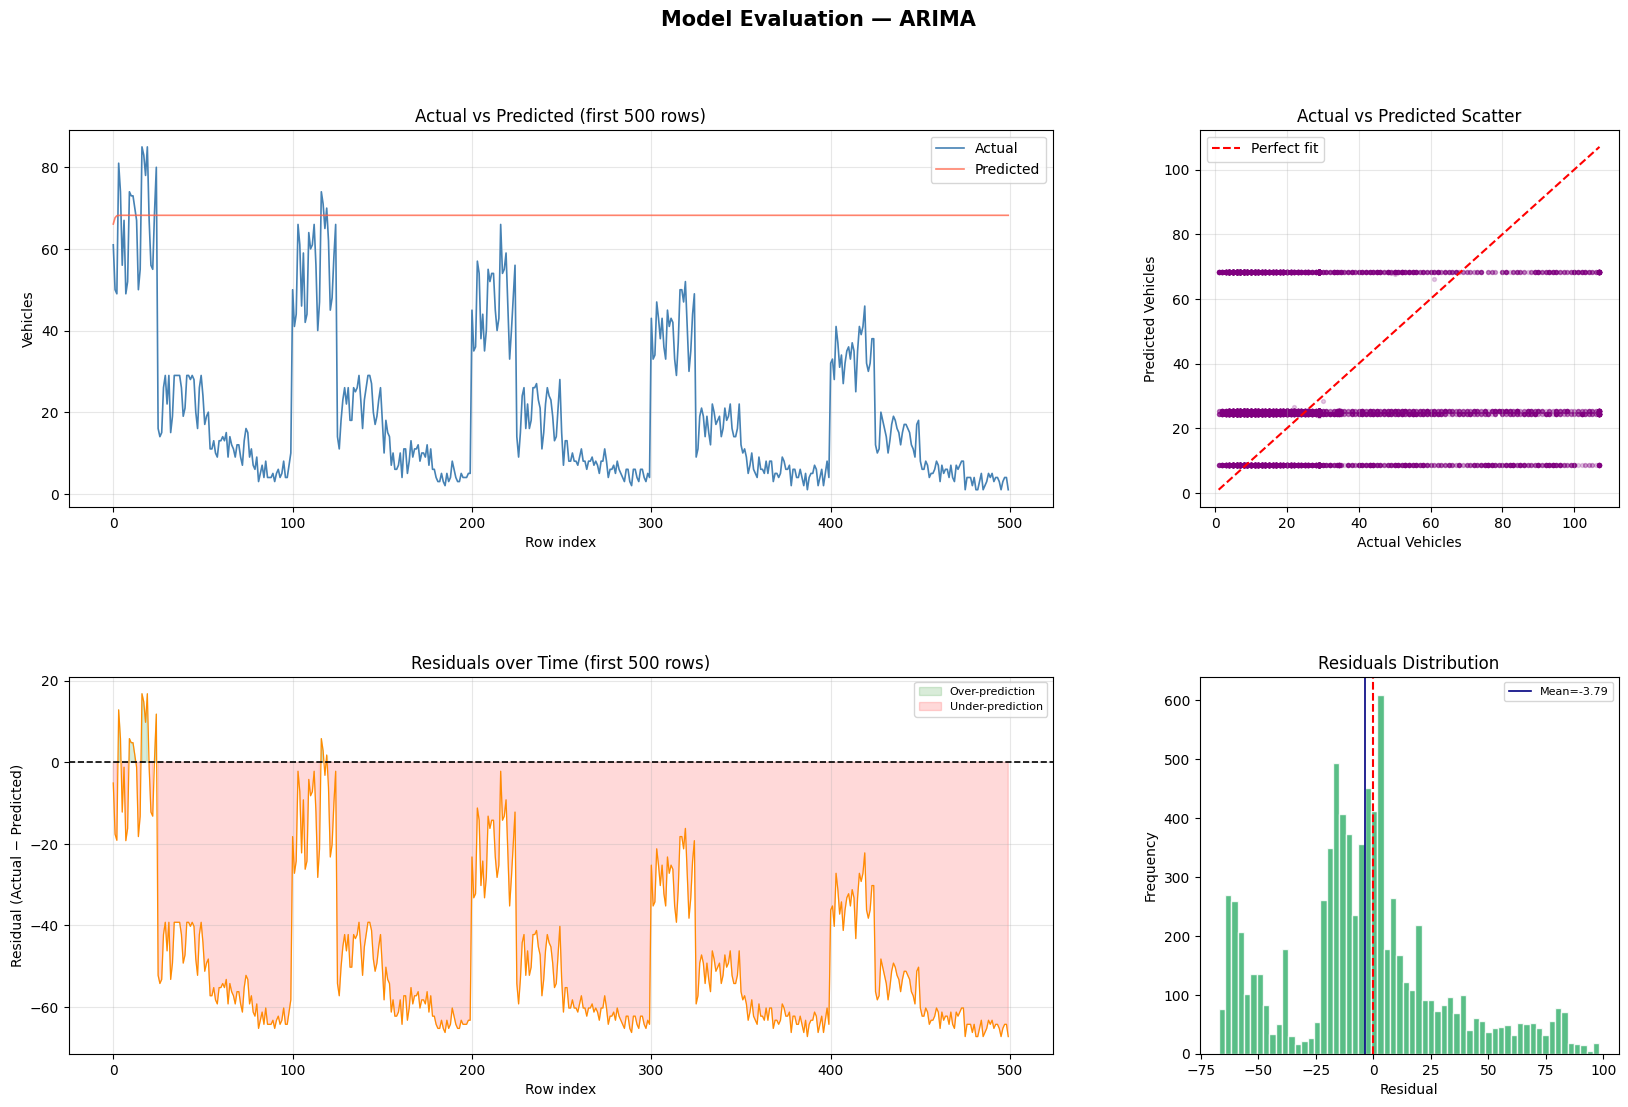

  ✔ eval_arima.png saved

  Per-junction plots …


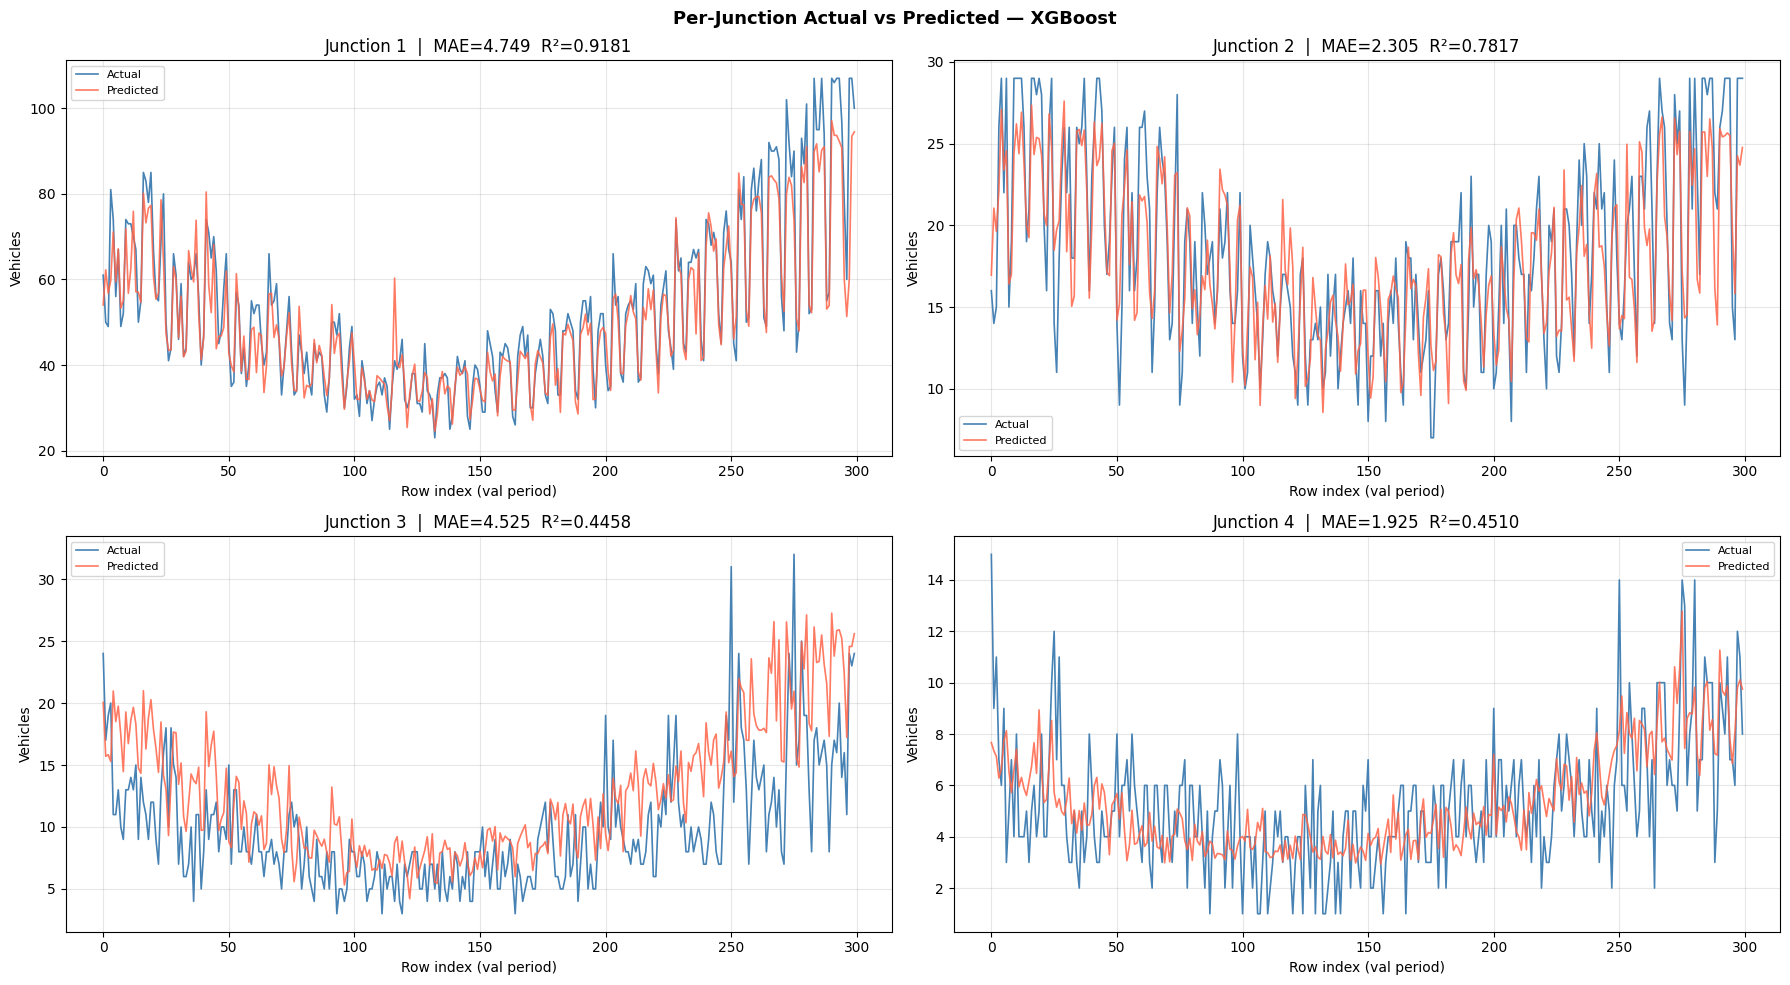

  ✔ per_junction_xgboost.png saved


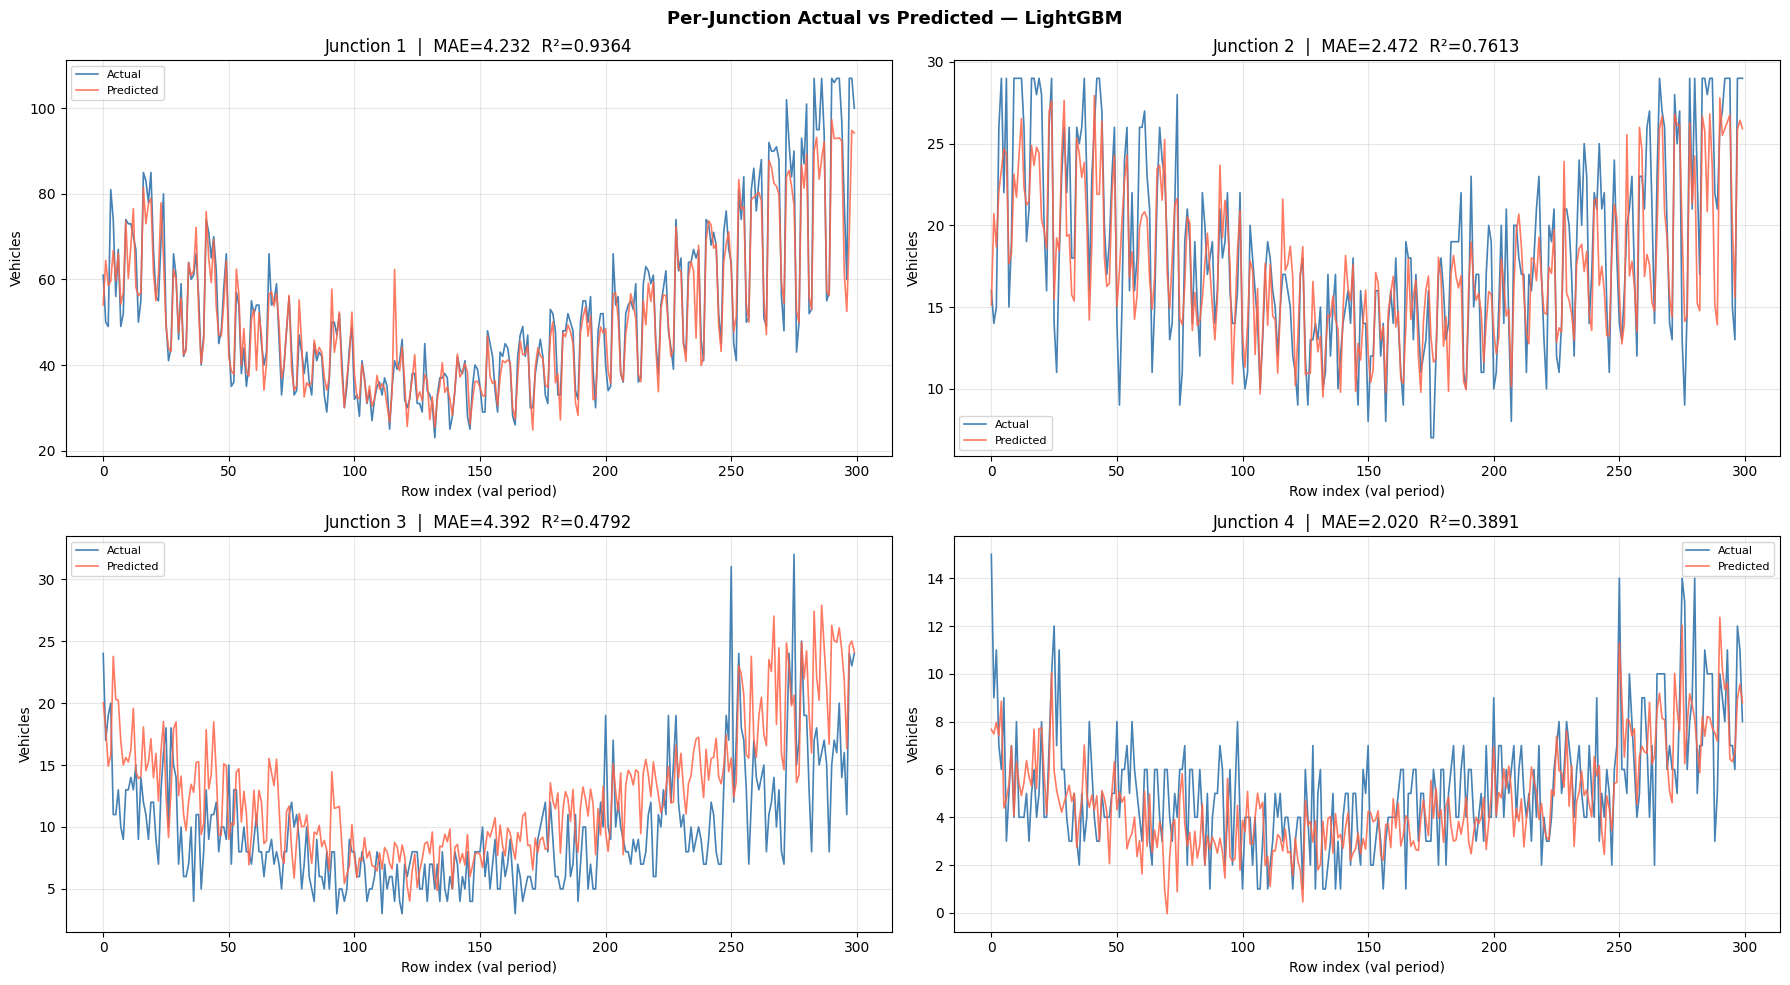

  ✔ per_junction_lightgbm.png saved


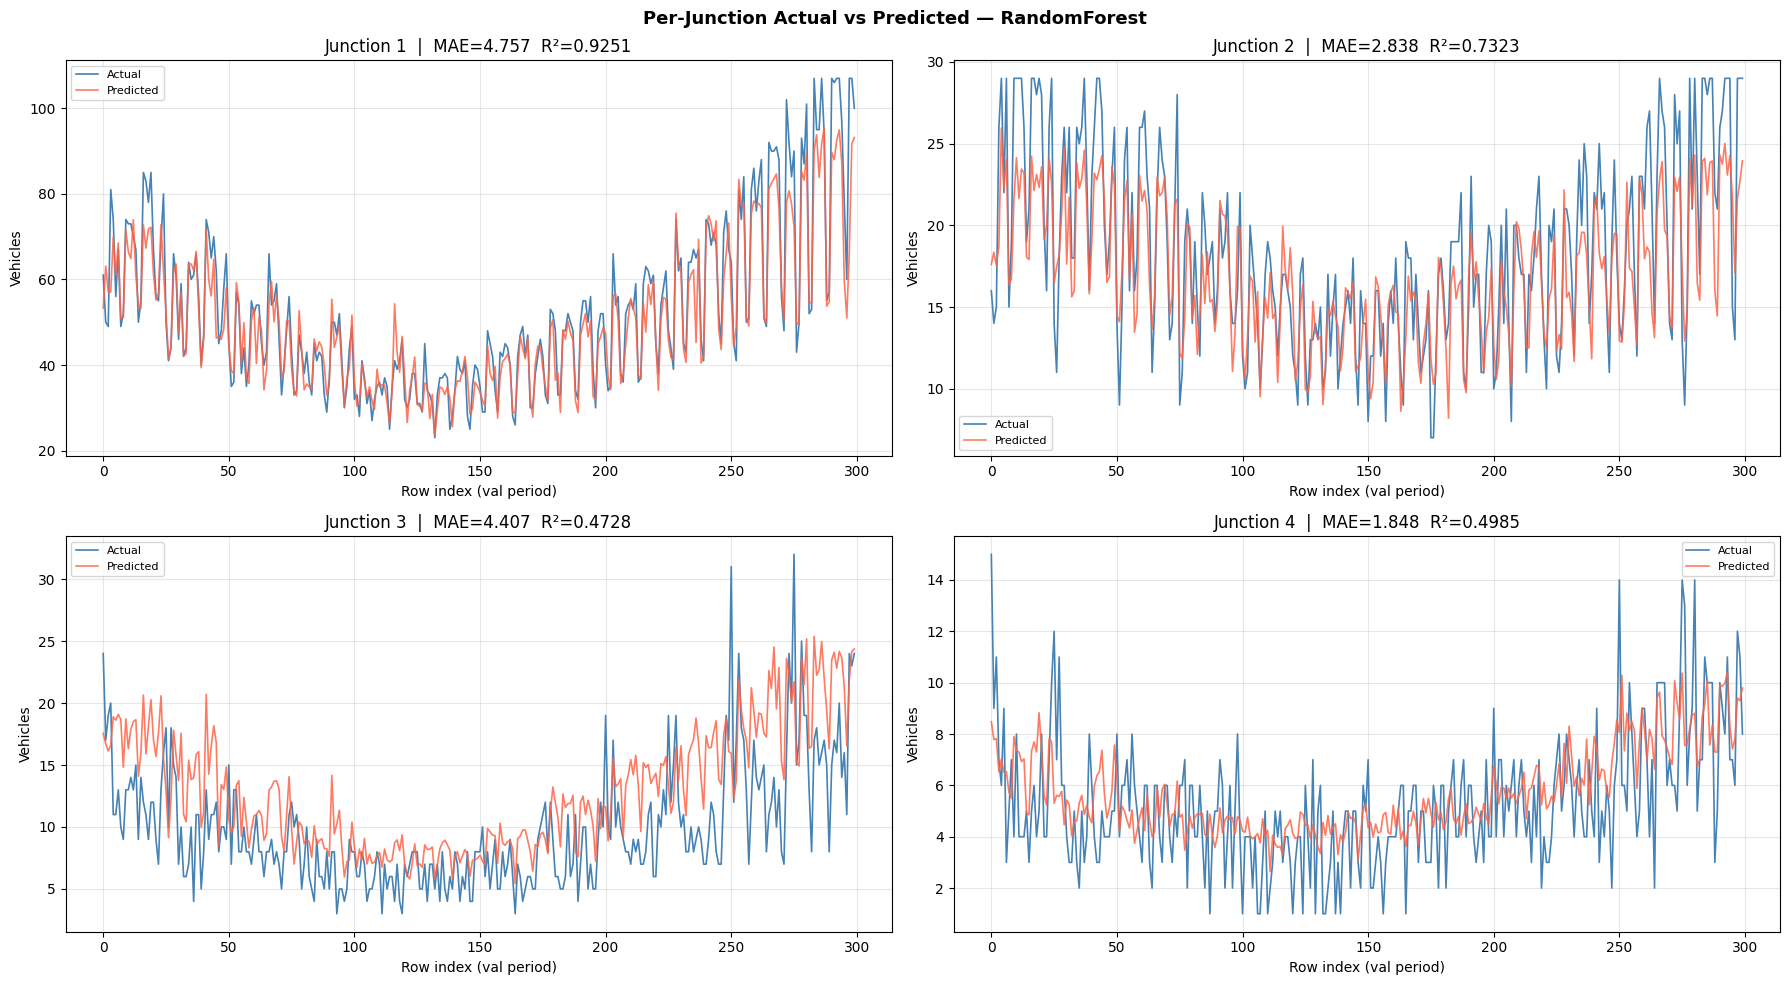

  ✔ per_junction_randomforest.png saved


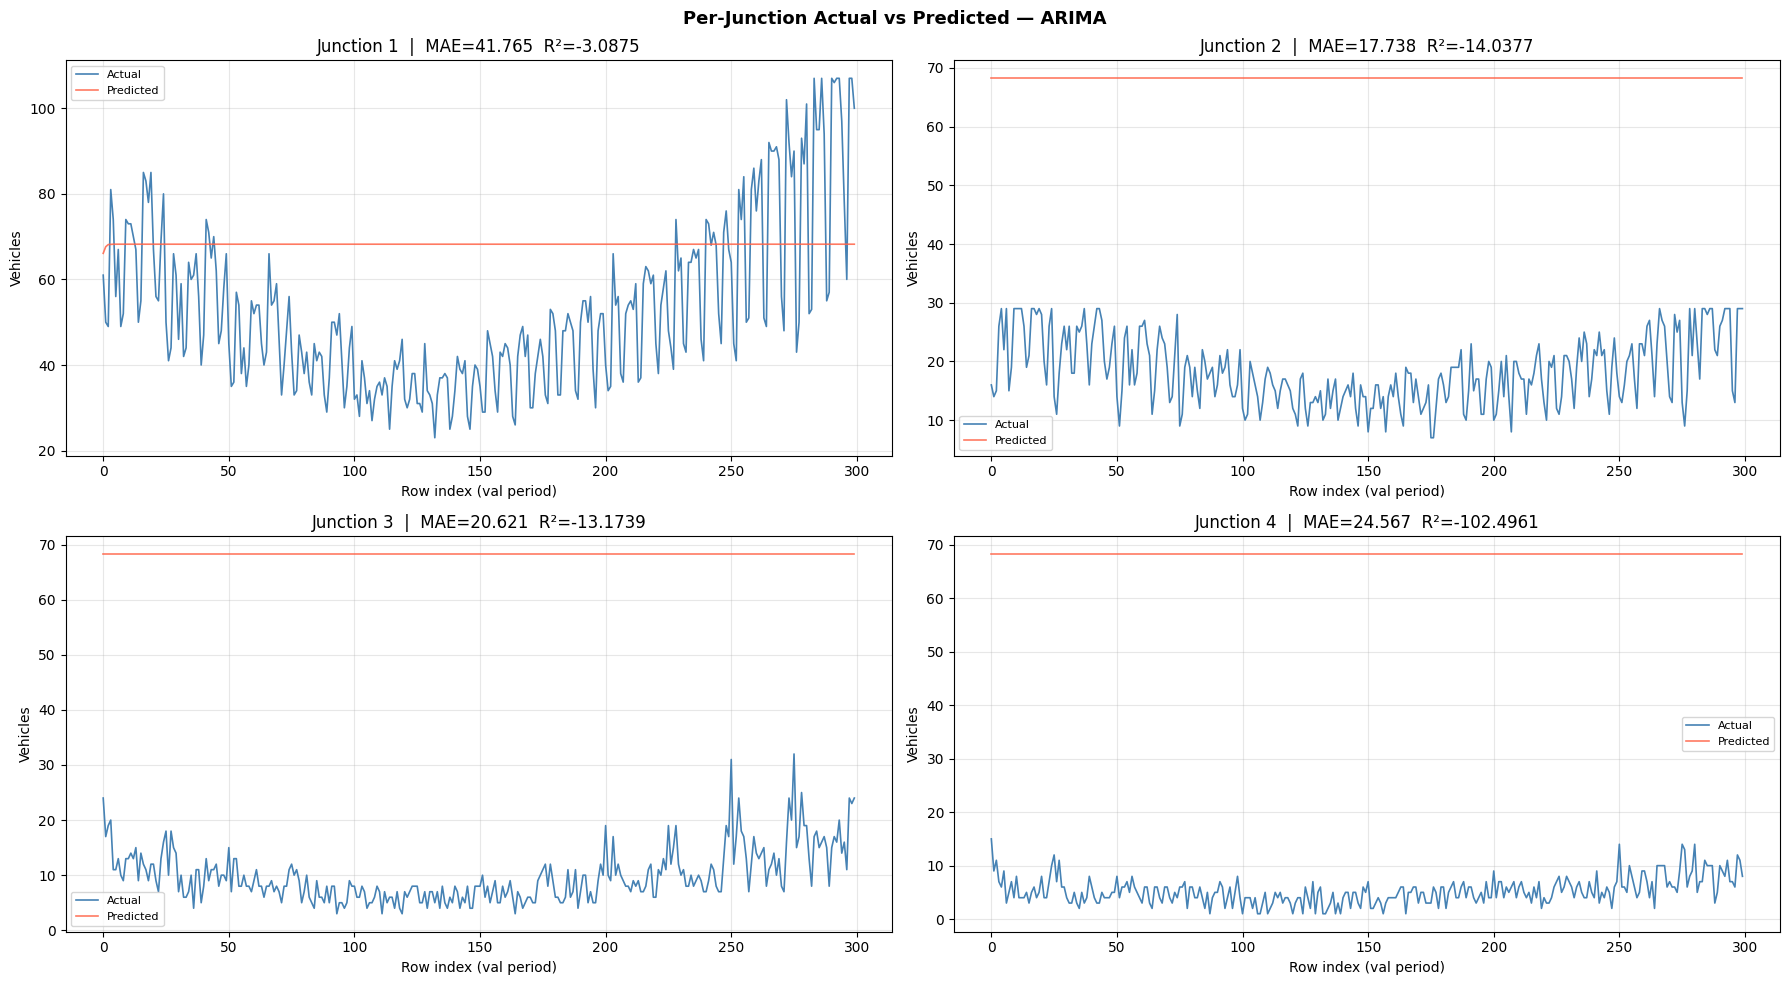

  ✔ per_junction_arima.png saved


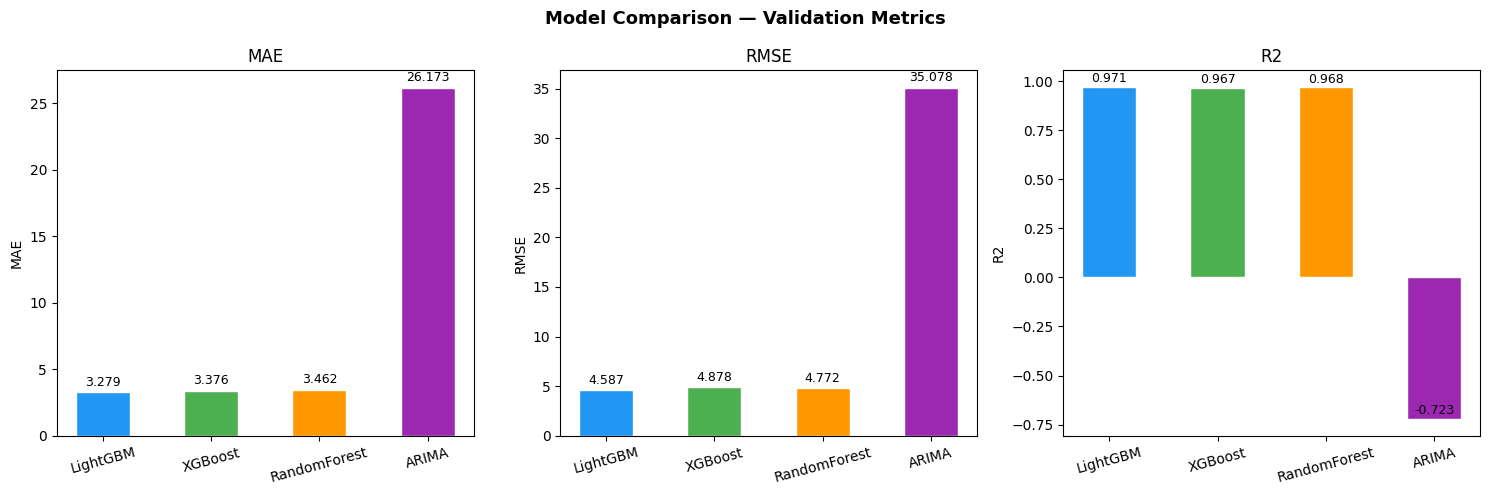


  ✔ model_comparison_bar.png saved

── 3C. Time-Series Cross-Validation (5-fold) ───────
  Loaded xgboost_model.pkl
  Loaded lightgbm_model.pkl
  Loaded rf_model.pkl

  Running CV on 48120 rows …

  Fold 1  train= 8020  val= 8020
    XGBoost         MAE=2.8233  RMSE=3.9174  R²=0.9216
    LightGBM        MAE=2.8646  RMSE=3.9319  R²=0.9210
    RandomForest    MAE=2.8785  RMSE=4.0142  R²=0.9176
  Fold 2  train=16040  val= 8020
    XGBoost         MAE=2.9370  RMSE=4.3140  R²=0.9415
    LightGBM        MAE=2.9244  RMSE=4.2505  R²=0.9433
    RandomForest    MAE=2.9565  RMSE=4.3348  R²=0.9410
  Fold 3  train=24060  val= 8020
    XGBoost         MAE=3.1363  RMSE=4.6569  R²=0.9432
    LightGBM        MAE=3.1620  RMSE=4.6745  R²=0.9428
    RandomForest    MAE=3.1702  RMSE=4.7456  R²=0.9410
  Fold 4  train=32080  val= 8020
    XGBoost         MAE=4.6164  RMSE=6.7801  R²=0.9229
    LightGBM        MAE=4.5312  RMSE=6.6474  R²=0.9259
    RandomForest    MAE=5.1545  RMSE=7.2759  R²=0.9112
  Fold 5  

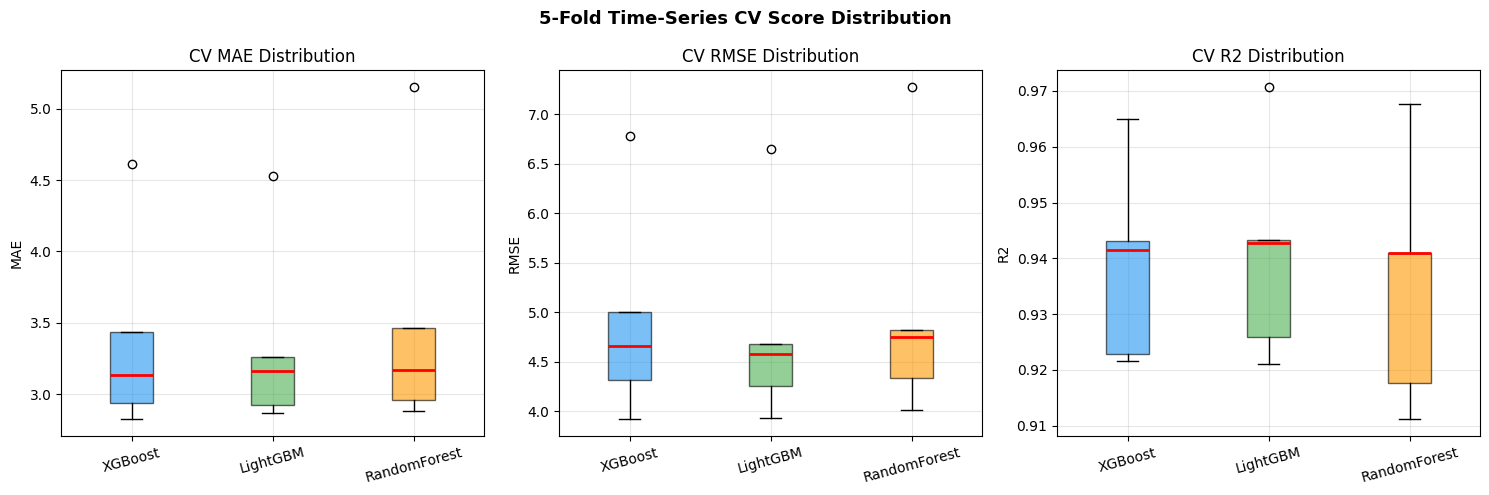

✔ cv_boxplot.png saved.

── Bias-Variance Diagnosis ─────────────────────────
  XGBoost         CV ratio=0.191  →  ✅  Good fit — stable and low MAE across folds
  LightGBM        CV ratio=0.182  →  ✅  Good fit — stable and low MAE across folds
  RandomForest    CV ratio=0.238  →  ✅  Good fit — stable and low MAE across folds

🏆 Best model (CV)       : LightGBM  MAE=3.3487 ± 0.6091
🏆 Best model (Val set)  : LightGBM  MAE=3.2793

  Plots saved to : C:\Users\syin\Downloads\Uber_project\Datasets\evaluation_plots

✅ Component 3 complete — ready for refinement.


In [14]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 3 — MODEL EVALUATION & CROSS-VALIDATION
#  Goal : Hourly traffic volume prediction at road junctions
# ═══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os, warnings, joblib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics         import mean_absolute_error, mean_squared_error, r2_score

# ── Paths ────────────────────────────────────────────────
SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
MODEL_DIR = os.path.join(SAVE_DIR, "models")
PLOT_DIR  = os.path.join(SAVE_DIR, "evaluation_plots")
os.makedirs(PLOT_DIR, exist_ok=True)

TARGET = "Vehicles"

# ── Load data ────────────────────────────────────────────
train_df = pd.read_csv(os.path.join(SAVE_DIR, "train_split.csv"))
val_df   = pd.read_csv(os.path.join(SAVE_DIR, "val_split.csv"))
preds_df = pd.read_csv(os.path.join(MODEL_DIR, "val_predictions.csv"))

FEATURE_COLS = pd.read_csv(
    os.path.join(SAVE_DIR, "feature_cols.csv")
)["feature"].tolist()

X_train = train_df[FEATURE_COLS].values
y_train = train_df[TARGET].values
X_val   = val_df[FEATURE_COLS].values
y_val   = val_df[TARGET].values

PRED_COLS   = [c for c in preds_df.columns if c.startswith("pred_")]
MODEL_NAMES = [c.replace("pred_", "") for c in PRED_COLS]

print(f"Models to evaluate : {MODEL_NAMES}")
print(f"Val rows           : {len(val_df)}")
print(f"Junctions          : {sorted(val_df['junction'].unique())}\n")

# ════════════════════════════════════════════════════════
#  3A.  METRICS TABLE
# ════════════════════════════════════════════════════════
print("── 3A. Validation Metrics ──────────────────────────")

metrics_rows = []
for col, name in zip(PRED_COLS, MODEL_NAMES):
    p    = preds_df[col].values
    y    = preds_df[TARGET].values
    mae  = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    r2   = r2_score(y, p)
    mape = np.mean(np.abs((y - p) / np.where(y == 0, 1, y))) * 100
    metrics_rows.append({
        "Model": name, "MAE": round(mae, 4), "RMSE": round(rmse, 4),
        "R2": round(r2, 4), "MAPE(%)": round(mape, 4)
    })
    print(f"  {name:<15} MAE={mae:.4f}  RMSE={rmse:.4f}  "
          f"R²={r2:.4f}  MAPE={mape:.2f}%")

metrics_df = pd.DataFrame(metrics_rows).sort_values("MAE").reset_index(drop=True)
metrics_df.to_csv(os.path.join(MODEL_DIR, "evaluation_metrics.csv"), index=False)
print(f"\n✔ evaluation_metrics.csv saved.")
print(f"🏆 Best model on val : {metrics_df.iloc[0]['Model']}  "
      f"MAE={metrics_df.iloc[0]['MAE']}")

# ── Per-junction metrics ─────────────────────────────────
print("\n── Per-Junction Metrics (best model) ───────────────")
best_col  = f"pred_{metrics_df.iloc[0]['Model']}"
jn_metrics = []
for jn in sorted(preds_df["junction"].unique()):
    mask = preds_df["junction"] == jn
    y_jn = preds_df.loc[mask, TARGET].values
    p_jn = preds_df.loc[mask, best_col].values
    mae  = mean_absolute_error(y_jn, p_jn)
    rmse = np.sqrt(mean_squared_error(y_jn, p_jn))
    r2   = r2_score(y_jn, p_jn)
    jn_metrics.append({"Junction": jn, "MAE": round(mae,4),
                        "RMSE": round(rmse,4), "R2": round(r2,4)})
    print(f"  Junction {jn} → MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}")

pd.DataFrame(jn_metrics).to_csv(
    os.path.join(MODEL_DIR, "per_junction_metrics.csv"), index=False)
print("✔ per_junction_metrics.csv saved.")

# ════════════════════════════════════════════════════════
#  3B.  EVALUATION PLOTS (per model)
# ════════════════════════════════════════════════════════
print("\n── 3B. Generating evaluation plots ─────────────────")

y_actual = preds_df[TARGET].values

for col, name in zip(PRED_COLS, MODEL_NAMES):
    y_pred    = preds_df[col].values
    residuals = y_actual - y_pred

    fig = plt.figure(figsize=(20, 12))
    fig.suptitle(f"Model Evaluation — {name}", fontsize=15, fontweight="bold")
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

    # Plot 1: Actual vs Predicted over time (first 500 pts)
    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(range(500), y_actual[:500],
             label="Actual", color="steelblue", linewidth=1.2)
    ax1.plot(range(500), y_pred[:500],
             label="Predicted", color="tomato", linewidth=1.2, alpha=0.8)
    ax1.set_title("Actual vs Predicted (first 500 rows)")
    ax1.set_xlabel("Row index")
    ax1.set_ylabel("Vehicles")
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Plot 2: Scatter actual vs predicted
    ax2 = fig.add_subplot(gs[0, 2])
    ax2.scatter(y_actual, y_pred, alpha=0.2, s=8, color="purple")
    lim = [min(y_actual.min(), y_pred.min()),
           max(y_actual.max(), y_pred.max())]
    ax2.plot(lim, lim, "r--", linewidth=1.5, label="Perfect fit")
    ax2.set_xlabel("Actual Vehicles")
    ax2.set_ylabel("Predicted Vehicles")
    ax2.set_title("Actual vs Predicted Scatter")
    ax2.legend()
    ax2.grid(alpha=0.3)

    # Plot 3: Residuals over time
    ax3 = fig.add_subplot(gs[1, :2])
    ax3.plot(range(500), residuals[:500],
             color="darkorange", linewidth=0.9)
    ax3.axhline(0, color="black", linewidth=1.2, linestyle="--")
    ax3.fill_between(range(500), residuals[:500], 0,
                     where=(residuals[:500] > 0),
                     color="green", alpha=0.15, label="Over-prediction")
    ax3.fill_between(range(500), residuals[:500], 0,
                     where=(residuals[:500] < 0),
                     color="red", alpha=0.15, label="Under-prediction")
    ax3.set_title("Residuals over Time (first 500 rows)")
    ax3.set_xlabel("Row index")
    ax3.set_ylabel("Residual (Actual − Predicted)")
    ax3.legend(fontsize=8)
    ax3.grid(alpha=0.3)

    # Plot 4: Residuals distribution
    ax4 = fig.add_subplot(gs[1, 2])
    ax4.hist(residuals, bins=60, color="mediumseagreen",
             edgecolor="white", alpha=0.85)
    ax4.axvline(0, color="red", linestyle="--", linewidth=1.5)
    ax4.axvline(np.mean(residuals), color="navy", linestyle="-",
                linewidth=1.2, label=f"Mean={np.mean(residuals):.2f}")
    ax4.set_title("Residuals Distribution")
    ax4.set_xlabel("Residual")
    ax4.set_ylabel("Frequency")
    ax4.legend(fontsize=8)

    path = os.path.join(PLOT_DIR, f"eval_{name.lower()}.png")
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"  ✔ eval_{name.lower()}.png saved")

# ── Per-junction plots for ALL models ────────────────────
print("\n  Per-junction plots …")
for col, name in zip(PRED_COLS, MODEL_NAMES):
    junctions = sorted(preds_df["junction"].unique())
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))
    axes = axes.flatten()
    fig.suptitle(f"Per-Junction Actual vs Predicted — {name}",
                 fontsize=13, fontweight="bold")

    for i, jn in enumerate(junctions):
        mask = preds_df["junction"] == jn
        jdf  = preds_df[mask].reset_index(drop=True)
        n    = min(300, len(jdf))

        axes[i].plot(range(n), jdf[TARGET].values[:n],
                     label="Actual", lw=1.2, color="steelblue")
        axes[i].plot(range(n), jdf[col].values[:n],
                     label="Predicted", lw=1.2, color="tomato", alpha=0.85)

        jn_mae = mean_absolute_error(jdf[TARGET], jdf[col])
        jn_r2  = r2_score(jdf[TARGET], jdf[col])
        axes[i].set_title(
            f"Junction {jn}  |  MAE={jn_mae:.3f}  R²={jn_r2:.4f}")
        axes[i].set_xlabel("Row index (val period)")
        axes[i].set_ylabel("Vehicles")
        axes[i].legend(fontsize=8)
        axes[i].grid(alpha=0.3)

    plt.tight_layout()
    path = os.path.join(PLOT_DIR, f"per_junction_{name.lower()}.png")
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"  ✔ per_junction_{name.lower()}.png saved")

# ── Metrics comparison bar chart ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Model Comparison — Validation Metrics",
             fontsize=13, fontweight="bold")

colors = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0"]
models = metrics_df["Model"].tolist()

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    vals = metrics_df[metric].tolist()
    bars = ax.bar(models, vals, color=colors[:len(models)],
                  edgecolor="white", width=0.5)
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01 * max(vals),
                f"{val:.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
path = os.path.join(PLOT_DIR, "model_comparison_bar.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"\n  ✔ model_comparison_bar.png saved")

# ════════════════════════════════════════════════════════
#  3C.  TIME-SERIES CROSS-VALIDATION (5-fold)
# ════════════════════════════════════════════════════════
print("\n── 3C. Time-Series Cross-Validation (5-fold) ───────")

# Load tree models (skip ARIMA for CV — too slow)
models_cv = {}
for mname, fname in [("XGBoost",     "xgboost_model.pkl"),
                      ("LightGBM",    "lightgbm_model.pkl"),
                      ("RandomForest","rf_model.pkl")]:
    pkl = os.path.join(MODEL_DIR, fname)
    if os.path.exists(pkl):
        models_cv[mname] = joblib.load(pkl)
        print(f"  Loaded {fname}")

# Combine train + val for full CV
X_full = np.vstack([X_train, X_val])
y_full = np.concatenate([y_train, y_val])

tscv       = TimeSeriesSplit(n_splits=5)
cv_results = {m: {"MAE": [], "RMSE": [], "R2": []} for m in models_cv}

print(f"\n  Running CV on {len(X_full)} rows …\n")
for fold, (tr_idx, vl_idx) in enumerate(tscv.split(X_full)):
    X_tr, X_vl = X_full[tr_idx], X_full[vl_idx]
    y_tr, y_vl = y_full[tr_idx], y_full[vl_idx]
    print(f"  Fold {fold+1}  train={len(tr_idx):>5}  val={len(vl_idx):>5}")

    for mname, model in models_cv.items():
        model.fit(X_tr, y_tr)
        preds = model.predict(X_vl)
        mae   = mean_absolute_error(y_vl, preds)
        rmse  = np.sqrt(mean_squared_error(y_vl, preds))
        r2    = r2_score(y_vl, preds)
        cv_results[mname]["MAE"].append(mae)
        cv_results[mname]["RMSE"].append(rmse)
        cv_results[mname]["R2"].append(r2)
        print(f"    {mname:<15} MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}")

# ── CV Summary table ─────────────────────────────────────
print("\n\n══ CROSS-VALIDATION SUMMARY ══════════════════════")
cv_rows = []
for mname, scores in cv_results.items():
    row = {
        "Model"    : mname,
        "MAE_mean" : round(np.mean(scores["MAE"]),  4),
        "MAE_std"  : round(np.std(scores["MAE"]),   4),
        "RMSE_mean": round(np.mean(scores["RMSE"]), 4),
        "RMSE_std" : round(np.std(scores["RMSE"]),  4),
        "R2_mean"  : round(np.mean(scores["R2"]),   4),
        "R2_std"   : round(np.std(scores["R2"]),    4),
    }
    cv_rows.append(row)
    print(f"  {mname:<15} "
          f"MAE={row['MAE_mean']} ± {row['MAE_std']}  "
          f"RMSE={row['RMSE_mean']} ± {row['RMSE_std']}  "
          f"R²={row['R2_mean']} ± {row['R2_std']}")

cv_df = pd.DataFrame(cv_rows).sort_values("MAE_mean").reset_index(drop=True)
cv_df.to_csv(os.path.join(MODEL_DIR, "cv_summary.csv"), index=False)
print(f"\n✔ cv_summary.csv saved.")

# ── CV Boxplot ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("5-Fold Time-Series CV Score Distribution",
             fontsize=13, fontweight="bold")

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    data   = [cv_results[m][metric] for m in cv_results]
    labels = list(cv_results.keys())
    bp = ax.boxplot(data, labels=labels, patch_artist=True,
                    medianprops={"color": "red", "linewidth": 2})
    colors_bp = ["#2196F3", "#4CAF50", "#FF9800"]
    for patch, color in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_title(f"CV {metric} Distribution")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(alpha=0.3)

plt.tight_layout()
path = os.path.join(PLOT_DIR, "cv_boxplot.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"✔ cv_boxplot.png saved.")

# ── Overfitting / underfitting diagnosis ─────────────────
print("\n── Bias-Variance Diagnosis ─────────────────────────")
for mname, scores in cv_results.items():
    mean_mae = np.mean(scores["MAE"])
    std_mae  = np.std(scores["MAE"])
    cv_ratio = std_mae / mean_mae   # coefficient of variation

    if mean_mae > 8:
        verdict = "⚠  HIGH BIAS (underfitting) — MAE is high across all folds"
    elif cv_ratio > 0.3:
        verdict = "⚠  HIGH VARIANCE (overfitting) — MAE varies a lot across folds"
    else:
        verdict = "✅  Good fit — stable and low MAE across folds"
    print(f"  {mname:<15} CV ratio={cv_ratio:.3f}  →  {verdict}")

# ── Final summary ────────────────────────────────────────
best_cv = cv_df.iloc[0]["Model"]
print(f"\n🏆 Best model (CV)       : {best_cv}  "
      f"MAE={cv_df.iloc[0]['MAE_mean']} ± {cv_df.iloc[0]['MAE_std']}")
print(f"🏆 Best model (Val set)  : {metrics_df.iloc[0]['Model']}  "
      f"MAE={metrics_df.iloc[0]['MAE']}")
print(f"\n  Plots saved to : {PLOT_DIR}")
print("\n✅ Component 3 complete — ready for refinement.")

✔ Loaded LightGBM model
  Train shape : (39960, 40)
  Val shape   : (8160, 40)
  Features    : 40

── Baseline (before refinement) ────────────────────
  MAE=3.2793  RMSE=4.5874  R²=0.9705

── 4A. Error Analysis ──────────────────────────────
  Worst hours (MAE):
hour
11    4.497918
0     4.479535
10    4.149812
12    3.929942
20    3.845593

  Error by junction:
              mean        max       std
junction                               
1         4.232480  44.897440  4.295752
2         2.472041  12.411068  2.009170
3         4.392002  18.996199  3.453302
4         2.020486  10.433879  1.543220

  Error by day_of_week:
day_of_week
0    3.346701
1    3.483682
2    3.099764
3    3.408141
4    3.216512
5    3.238597
6    3.170030

  High-error rows (top 5%, abs_error ≥ 9.26): 408 rows
  High-error hour distribution:
  hour
11    44
21    37
0     35
10    31
20    30
  High-error junction distribution:
  junction
3    198
1    192
2     17
4      1


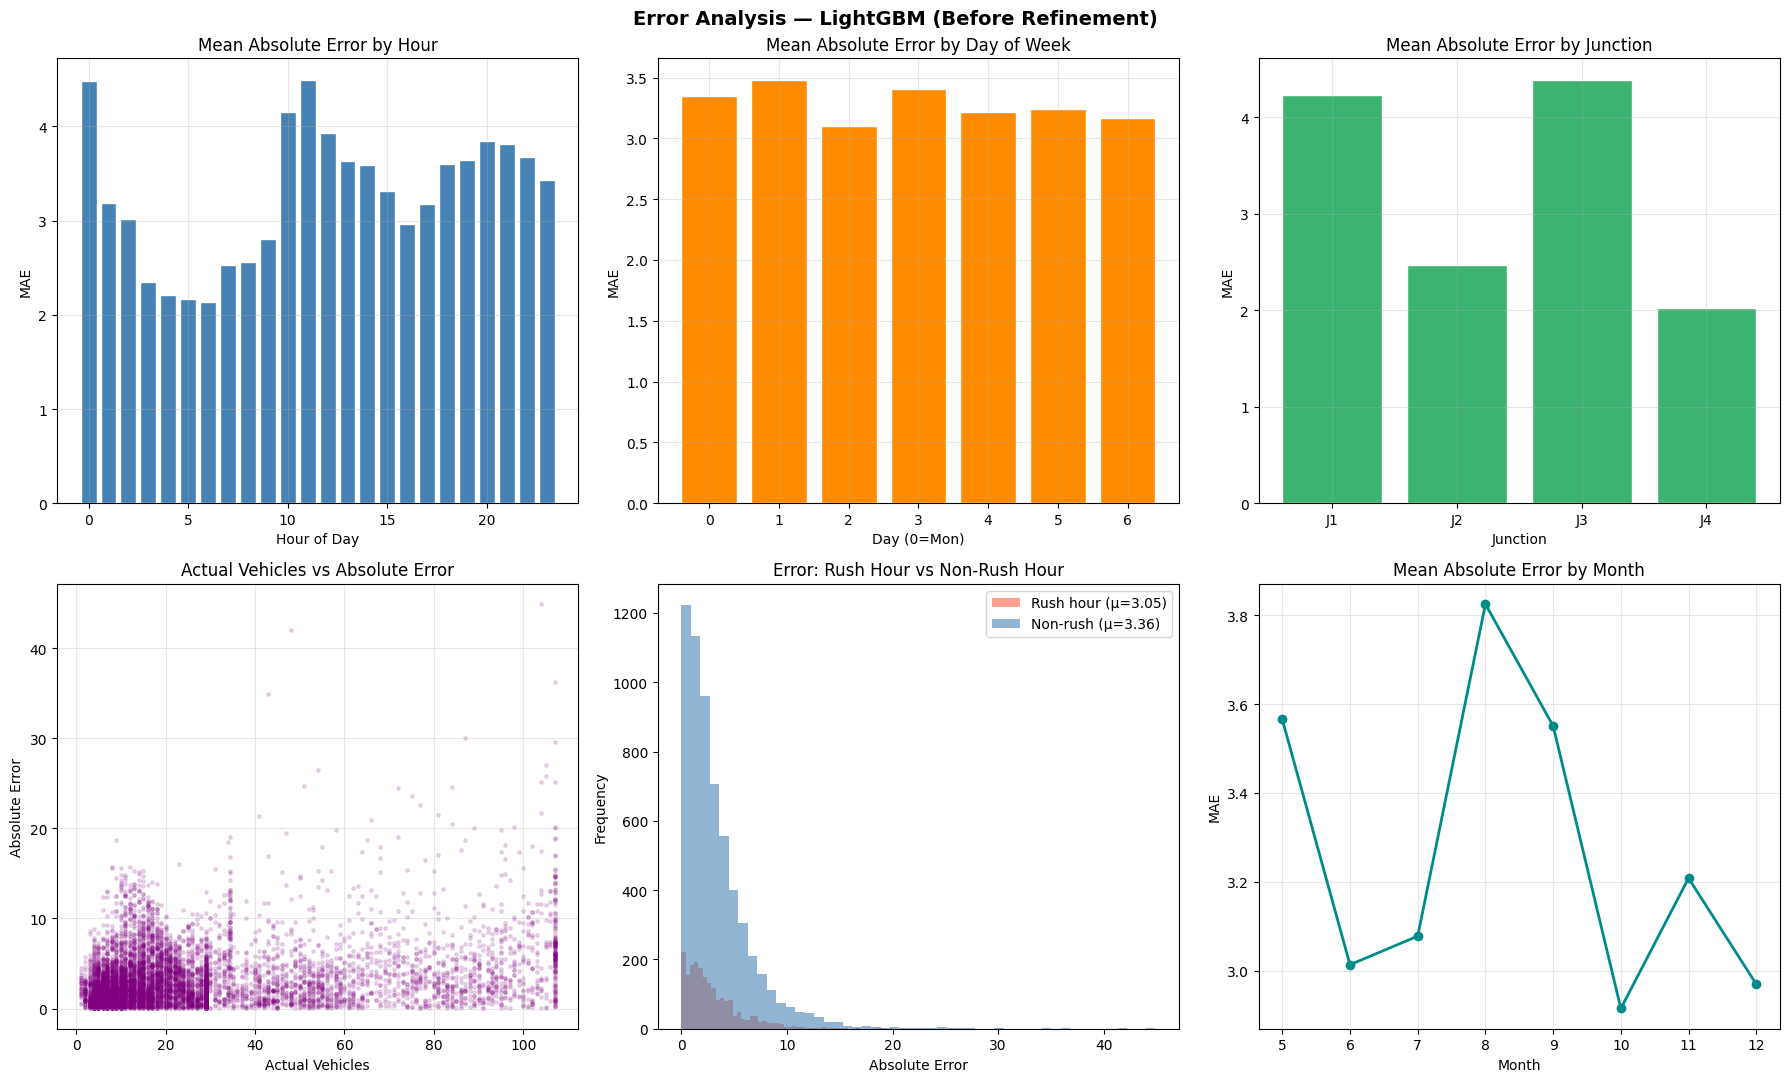


  ✔ error_analysis.png saved

── 4B. Learning Curve ──────────────────────────────


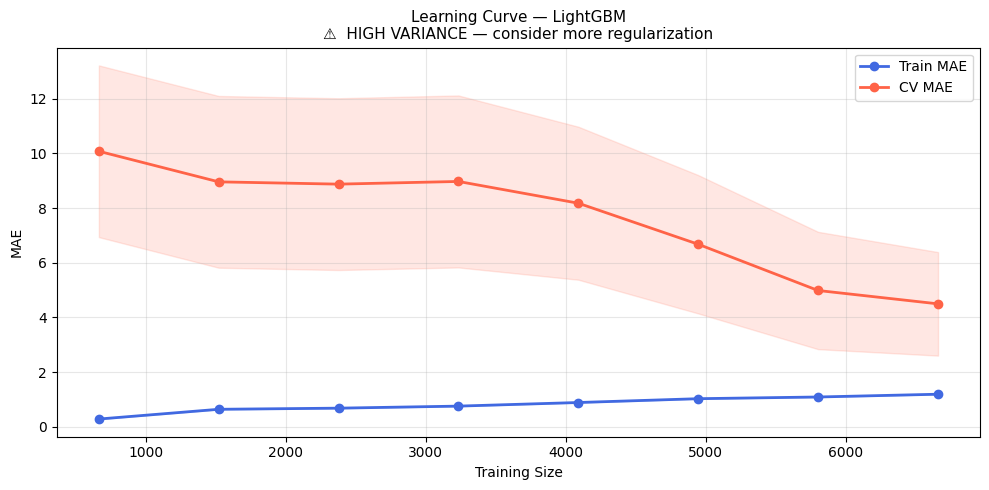

  ⚠  HIGH VARIANCE — consider more regularization
  Train MAE @ full data : 1.1880
  CV MAE    @ full data : 4.4957
  Gap                   : 3.3076
  ✔ learning_curve_lightgbm.png saved

── 4C. Feature Importance ──────────────────────────
  Top 15 features:
         feature  importance
        junction        1992
            hour        1411
 rolling_std_24h        1269
       temp_norm        1192
 rolling_mean_6h        1168
  rolling_std_6h        1133
  rolling_max_6h         959
rolling_mean_24h         946
            pres         862
        ewma_12h         845
        ewma_24h         825
          lag_3h         757
 rolling_mean_3h         756
        lag_168h         747
          lag_6h         733


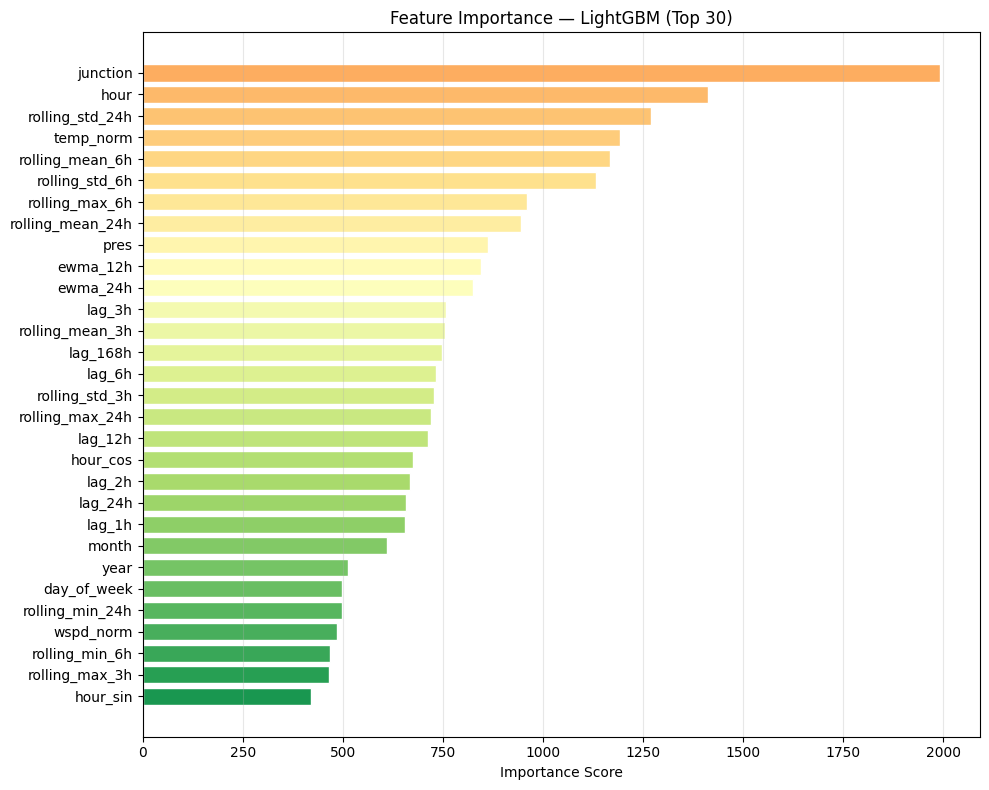

  ✔ feature_importance_lightgbm.png saved

  Total importance sum  : 25973
  Threshold (0.5%)      : 129.87
  Features removed (6): ['time_of_day_enc', 'is_workday', 'is_rush_hour', 'is_holiday', 'is_special_event', 'is_weekend']
  Features retained     : 34

── 4D. Fine-Tuning LightGBM (GridSearch) ───────────
Fitting 5 folds for each of 2187 candidates, totalling 10935 fits

  Best fine-tuned params:
    learning_rate             : 0.03
    max_depth                 : 7
    min_child_samples         : 20
    n_estimators              : 500
    num_leaves                : 79
    reg_alpha                 : 0.1
    reg_lambda                : 0

── 4E. Before vs After Refinement ─────────────────

  Metric       Before      After          Δ    Better?
  --------------------------------------------------
  MAE          3.2793     3.2824    +0.0031          ❌
  RMSE         4.5874     4.6361    +0.0487          ❌
  R²           0.9705     0.9699    -0.0006          ❌

  Per-junction (aft

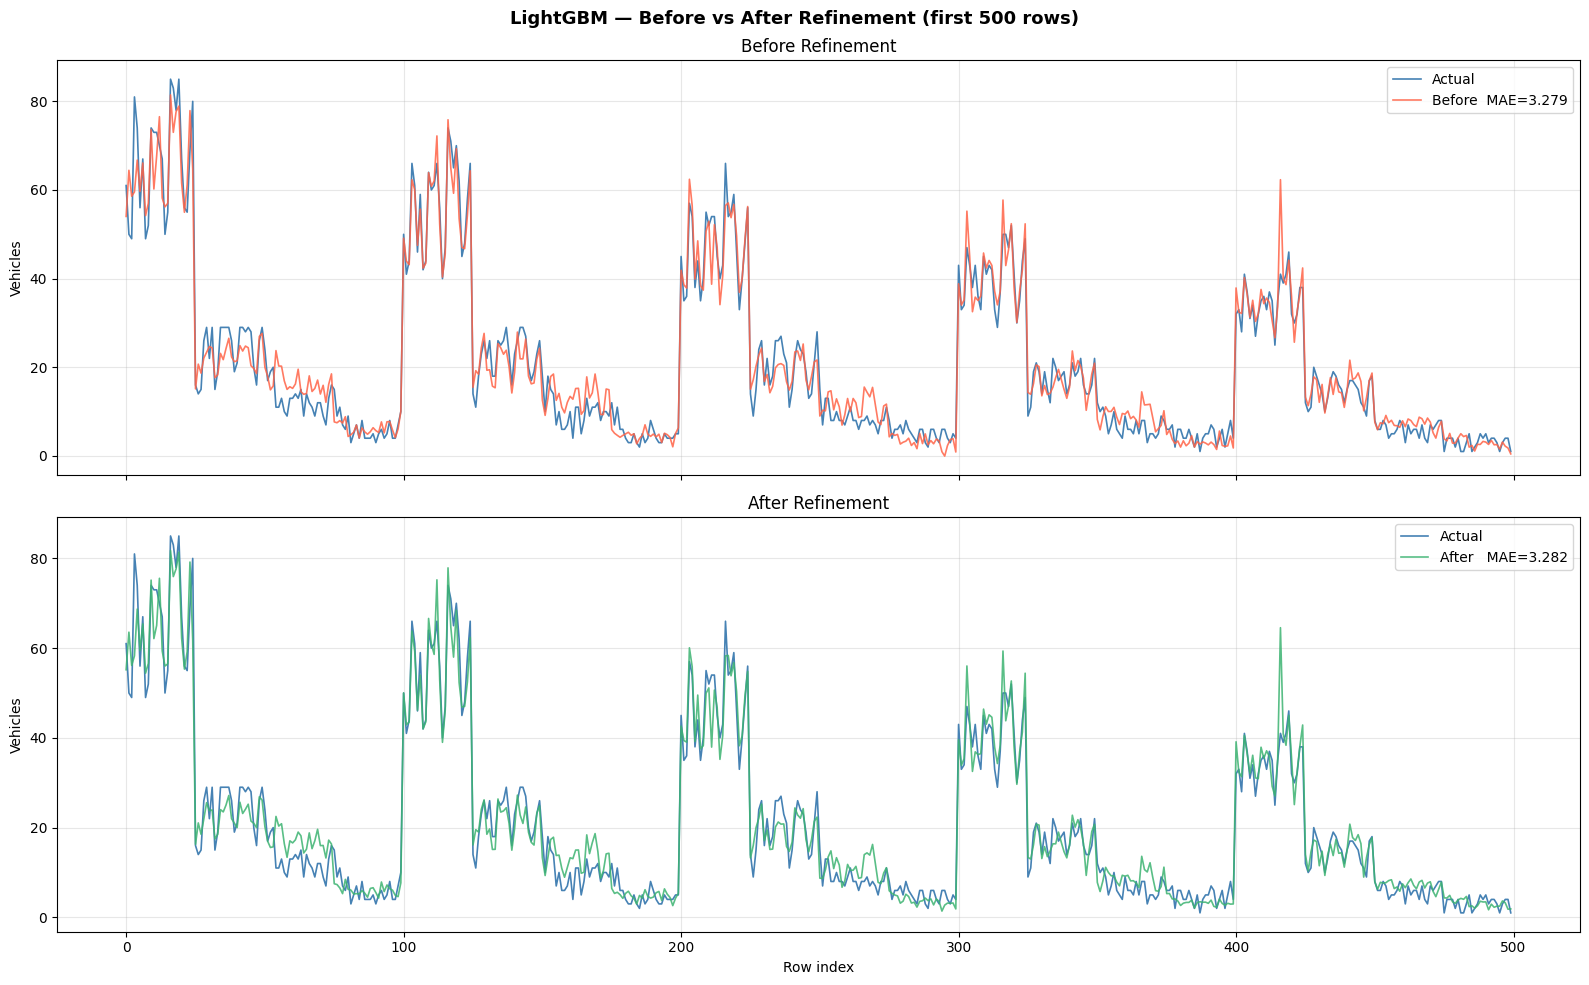

  ✔ before_vs_after_refinement.png saved
  ✔ final_per_junction.png saved

── 4G. Saving final model ──────────────────────────
  ✔ FINAL_lightgbm_model.pkl saved
  ✔ refined_feature_cols.csv saved  (34 features)
  ✔ final_predictions.csv saved
  ✔ refinement_summary.csv saved

╔══════════════════════════════════════════════════╗
║           FINAL MODEL SUMMARY                    ║
╠══════════════════════════════════════════════════╣
║  Model      : LightGBM (refined)                 ║
║  Features   : 34  (from 40 original)              ║
║  MAE        : 3.2824  (was 3.2793)           ║
║  RMSE       : 4.6361  (was 4.5874)           ║
║  R²         : 0.9699  (was 0.9705)              ║
║  MAPE       : 22.19%                            ║
╚══════════════════════════════════════════════════╝

✅ Component 4 complete — model refinement done.


In [20]:
# ═══════════════════════════════════════════════════════════
#  COMPONENT 4 — MODEL REFINEMENT
#  Goal : Hourly traffic volume prediction at road junctions
#  - Error analysis (bias/variance, error patterns)
#  - Feature importance & redundant feature removal
#  - Fine-tune best model (LightGBM) with GridSearch
#  - Compare before vs after refinement
#  - Save final model
# ═══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os, warnings, joblib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
warnings.filterwarnings("ignore")

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, learning_curve
from sklearn.metrics         import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb

# ── Paths ────────────────────────────────────────────────
SAVE_DIR  = r"C:\Users\syin\Downloads\Uber_project\Datasets"
MODEL_DIR = os.path.join(SAVE_DIR, "models")
PLOT_DIR  = os.path.join(SAVE_DIR, "evaluation_plots")
os.makedirs(PLOT_DIR, exist_ok=True)

TARGET = "Vehicles"

# ── Load data ────────────────────────────────────────────
train_df = pd.read_csv(os.path.join(SAVE_DIR, "train_split.csv"))
val_df   = pd.read_csv(os.path.join(SAVE_DIR, "val_split.csv"))
preds_df = pd.read_csv(os.path.join(MODEL_DIR, "val_predictions.csv"))

FEATURE_COLS = pd.read_csv(
    os.path.join(SAVE_DIR, "feature_cols.csv")
)["feature"].tolist()

X_train = train_df[FEATURE_COLS].values
y_train = train_df[TARGET].values
X_val   = val_df[FEATURE_COLS].values
y_val   = val_df[TARGET].values

# ── Load best model (LightGBM) ───────────────────────────
best_model = joblib.load(os.path.join(MODEL_DIR, "lightgbm_model.pkl"))
print("✔ Loaded LightGBM model")
print(f"  Train shape : {X_train.shape}")
print(f"  Val shape   : {X_val.shape}")
print(f"  Features    : {len(FEATURE_COLS)}\n")

# Baseline performance (before refinement)
y_pred_before = best_model.predict(X_val)
mae_before  = mean_absolute_error(y_val, y_pred_before)
rmse_before = np.sqrt(mean_squared_error(y_val, y_pred_before))
r2_before   = r2_score(y_val, y_pred_before)
print(f"── Baseline (before refinement) ────────────────────")
print(f"  MAE={mae_before:.4f}  RMSE={rmse_before:.4f}  R²={r2_before:.4f}\n")

# ════════════════════════════════════════════════════════
#  4A.  ERROR ANALYSIS
#  Understand WHERE and WHEN the model makes errors
# ════════════════════════════════════════════════════════
print("── 4A. Error Analysis ──────────────────────────────")

residuals      = y_val - y_pred_before
abs_errors     = np.abs(residuals)
pct_errors     = abs_errors / np.where(y_val == 0, 1, y_val) * 100

error_df = val_df.copy()
error_df["predicted"]  = y_pred_before
error_df["residual"]   = residuals
error_df["abs_error"]  = abs_errors
error_df["pct_error"]  = pct_errors

# ── Error by hour ────────────────────────────────────────
hourly_err = error_df.groupby("hour")["abs_error"].mean()
print(f"  Worst hours (MAE):")
print(hourly_err.sort_values(ascending=False).head(5).to_string())

# ── Error by junction ────────────────────────────────────
print(f"\n  Error by junction:")
jn_err = error_df.groupby("junction")["abs_error"].agg(["mean","max","std"])
print(jn_err.to_string())

# ── Error by day_of_week ─────────────────────────────────
print(f"\n  Error by day_of_week:")
dow_err = error_df.groupby("day_of_week")["abs_error"].mean()
print(dow_err.to_string())

# ── High-error rows (top 5%) ─────────────────────────────
threshold_95 = np.percentile(abs_errors, 95)
high_err     = error_df[error_df["abs_error"] >= threshold_95]
print(f"\n  High-error rows (top 5%, abs_error ≥ {threshold_95:.2f}): "
      f"{len(high_err)} rows")
print(f"  High-error hour distribution:\n"
      f"  {high_err['hour'].value_counts().head(5).to_string()}")
print(f"  High-error junction distribution:\n"
      f"  {high_err['junction'].value_counts().to_string()}")

# ── Error analysis plots ─────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Error Analysis — LightGBM (Before Refinement)",
             fontsize=14, fontweight="bold")

# 1. MAE by hour
axes[0,0].bar(hourly_err.index, hourly_err.values, color="steelblue",
              edgecolor="white")
axes[0,0].set_title("Mean Absolute Error by Hour")
axes[0,0].set_xlabel("Hour of Day")
axes[0,0].set_ylabel("MAE")
axes[0,0].grid(alpha=0.3)

# 2. MAE by day of week
axes[0,1].bar(dow_err.index, dow_err.values, color="darkorange",
              edgecolor="white")
axes[0,1].set_title("Mean Absolute Error by Day of Week")
axes[0,1].set_xlabel("Day (0=Mon)")
axes[0,1].set_ylabel("MAE")
axes[0,1].grid(alpha=0.3)

# 3. MAE by junction
jn_mean = error_df.groupby("junction")["abs_error"].mean()
axes[0,2].bar([f"J{j}" for j in jn_mean.index], jn_mean.values,
              color="mediumseagreen", edgecolor="white")
axes[0,2].set_title("Mean Absolute Error by Junction")
axes[0,2].set_xlabel("Junction")
axes[0,2].set_ylabel("MAE")
axes[0,2].grid(alpha=0.3)

# 4. Actual vs error scatter (heteroscedasticity check)
axes[1,0].scatter(y_val, abs_errors, alpha=0.15, s=6, color="purple")
axes[1,0].set_title("Actual Vehicles vs Absolute Error")
axes[1,0].set_xlabel("Actual Vehicles")
axes[1,0].set_ylabel("Absolute Error")
axes[1,0].grid(alpha=0.3)

# 5. Error distribution by rush hour
rush_err     = error_df[error_df["is_rush_hour"] == 1]["abs_error"]
non_rush_err = error_df[error_df["is_rush_hour"] == 0]["abs_error"]
axes[1,1].hist(rush_err,     bins=50, alpha=0.6, color="tomato",
               label=f"Rush hour (μ={rush_err.mean():.2f})")
axes[1,1].hist(non_rush_err, bins=50, alpha=0.6, color="steelblue",
               label=f"Non-rush (μ={non_rush_err.mean():.2f})")
axes[1,1].set_title("Error: Rush Hour vs Non-Rush Hour")
axes[1,1].set_xlabel("Absolute Error")
axes[1,1].set_ylabel("Frequency")
axes[1,1].legend()

# 6. Error by month
month_err = error_df.groupby("month")["abs_error"].mean()
axes[1,2].plot(month_err.index, month_err.values, "o-",
               color="darkcyan", linewidth=2, markersize=6)
axes[1,2].set_title("Mean Absolute Error by Month")
axes[1,2].set_xlabel("Month")
axes[1,2].set_ylabel("MAE")
axes[1,2].grid(alpha=0.3)

plt.tight_layout()
path = os.path.join(PLOT_DIR, "error_analysis.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"\n  ✔ error_analysis.png saved")

# ════════════════════════════════════════════════════════
#  4B.  LEARNING CURVE (bias-variance check)
# ════════════════════════════════════════════════════════
print("\n── 4B. Learning Curve ──────────────────────────────")

train_sizes, train_scores, val_scores = learning_curve(
    best_model, X_train, y_train,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    verbose=0
)

train_mean = -train_scores.mean(axis=1)
val_mean   = -val_scores.mean(axis=1)
train_std  =  train_scores.std(axis=1)
val_std    =  val_scores.std(axis=1)

gap = val_mean[-1] - train_mean[-1]
if gap > 3:
    lc_diagnosis = "⚠  HIGH VARIANCE — consider more regularization"
elif train_mean[-1] > 5:
    lc_diagnosis = "⚠  HIGH BIAS — model underfitting"
else:
    lc_diagnosis = "✅  Good fit — gap between train/val MAE is acceptable"

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_sizes, train_mean, "o-", color="royalblue",
        linewidth=2, label="Train MAE")
ax.plot(train_sizes, val_mean,   "o-", color="tomato",
        linewidth=2, label="CV MAE")
ax.fill_between(train_sizes,
                train_mean - train_std, train_mean + train_std,
                alpha=0.15, color="royalblue")
ax.fill_between(train_sizes,
                val_mean   - val_std,   val_mean   + val_std,
                alpha=0.15, color="tomato")
ax.set_title(f"Learning Curve — LightGBM\n{lc_diagnosis}", fontsize=11)
ax.set_xlabel("Training Size")
ax.set_ylabel("MAE")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
path = os.path.join(PLOT_DIR, "learning_curve_lightgbm.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"  {lc_diagnosis}")
print(f"  Train MAE @ full data : {train_mean[-1]:.4f}")
print(f"  CV MAE    @ full data : {val_mean[-1]:.4f}")
print(f"  Gap                   : {gap:.4f}")
print(f"  ✔ learning_curve_lightgbm.png saved")

# ════════════════════════════════════════════════════════
#  4C.  FEATURE IMPORTANCE & REMOVAL OF LOW-VALUE FEATURES
# ════════════════════════════════════════════════════════
print("\n── 4C. Feature Importance ──────────────────────────")

importances  = best_model.feature_importances_
feat_imp_df  = pd.DataFrame({
    "feature"   : FEATURE_COLS,
    "importance": importances
}).sort_values("importance", ascending=False).reset_index(drop=True)

feat_imp_df.to_csv(os.path.join(MODEL_DIR, "feature_importance.csv"),
                   index=False)

print(f"  Top 15 features:")
print(feat_imp_df.head(15).to_string(index=False))

# ── Plot feature importance ──────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
top_n  = min(30, len(feat_imp_df))
top_df = feat_imp_df.head(top_n)
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, top_n))[::-1]
ax.barh(top_df["feature"][::-1], top_df["importance"][::-1],
        color=colors, edgecolor="white")
ax.set_title(f"Feature Importance — LightGBM (Top {top_n})")
ax.set_xlabel("Importance Score")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
path = os.path.join(PLOT_DIR, "feature_importance_lightgbm.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"  ✔ feature_importance_lightgbm.png saved")

# ── Remove low-importance features ──────────────────────
total_imp   = feat_imp_df["importance"].sum()
threshold   = total_imp * 0.005          # < 0.5% of total importance
low_feats   = feat_imp_df[
    feat_imp_df["importance"] < threshold
]["feature"].tolist()
good_feats  = feat_imp_df[
    feat_imp_df["importance"] >= threshold
]["feature"].tolist()

print(f"\n  Total importance sum  : {total_imp}")
print(f"  Threshold (0.5%)      : {threshold:.2f}")
print(f"  Features removed ({len(low_feats)}): {low_feats}")
print(f"  Features retained     : {len(good_feats)}")

X_train_ref = train_df[good_feats].values
X_val_ref   = val_df[good_feats].values

# ════════════════════════════════════════════════════════
#  4D.  FINE-TUNE LightGBM (GridSearch on refined features)
# ════════════════════════════════════════════════════════
print("\n── 4D. Fine-Tuning LightGBM (GridSearch) ───────────")

# Narrow grid around best params from Component 2
# Best from C2: n_estimators=600, max_depth=6, learning_rate=0.05,
#               num_leaves=63, subsample=1.0, colsample_bytree=1.0,
#               min_child_samples=20, reg_alpha=0, reg_lambda=0

fine_grid = {
    "n_estimators"      : [500, 600, 700],
    "learning_rate"     : [0.03, 0.05, 0.07],
    "num_leaves"        : [47, 63, 79],
    "max_depth"         : [5, 6, 7],
    "min_child_samples" : [15, 20, 30],
    "reg_alpha"         : [0, 0.05, 0.1],
    "reg_lambda"        : [0, 0.1, 0.5],
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    lgb.LGBMRegressor(
        subsample=1.0, colsample_bytree=1.0,
        random_state=42, n_jobs=-1, verbose=-1
    ),
    fine_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)
grid_search.fit(X_train_ref, y_train)
final_model = grid_search.best_estimator_

print(f"\n  Best fine-tuned params:")
for k, v in grid_search.best_params_.items():
    print(f"    {k:<25} : {v}")

# ════════════════════════════════════════════════════════
#  4E.  BEFORE vs AFTER COMPARISON
# ════════════════════════════════════════════════════════
print("\n── 4E. Before vs After Refinement ─────────────────")

y_pred_final = final_model.predict(X_val_ref)
mae_final    = mean_absolute_error(y_val,  y_pred_final)
rmse_final   = np.sqrt(mean_squared_error(y_val, y_pred_final))
r2_final     = r2_score(y_val, y_pred_final)
mape_final   = np.mean(np.abs(
    (y_val - y_pred_final) / np.where(y_val == 0, 1, y_val)
)) * 100

print(f"\n  {'Metric':<8} {'Before':>10} {'After':>10} {'Δ':>10} {'Better?':>10}")
print(f"  {'-'*50}")
print(f"  {'MAE':<8} {mae_before:>10.4f} {mae_final:>10.4f} "
      f"{mae_final - mae_before:>+10.4f} "
      f"{'✅' if mae_final < mae_before else '❌':>10}")
print(f"  {'RMSE':<8} {rmse_before:>10.4f} {rmse_final:>10.4f} "
      f"{rmse_final - rmse_before:>+10.4f} "
      f"{'✅' if rmse_final < rmse_before else '❌':>10}")
print(f"  {'R²':<8} {r2_before:>10.4f} {r2_final:>10.4f} "
      f"{r2_final - r2_before:>+10.4f} "
      f"{'✅' if r2_final > r2_before else '❌':>10}")

# ── Per-junction after refinement ───────────────────────
print(f"\n  Per-junction (after refinement):")
val_ref_df = val_df.copy()
val_ref_df["pred_final"] = y_pred_final
for jn in sorted(val_df["junction"].unique()):
    mask = val_ref_df["junction"] == jn
    y_jn = val_ref_df.loc[mask, TARGET].values
    p_jn = val_ref_df.loc[mask, "pred_final"].values
    print(f"    Junction {jn} → MAE={mean_absolute_error(y_jn,p_jn):.4f}  "
          f"R²={r2_score(y_jn,p_jn):.4f}")

# ════════════════════════════════════════════════════════
#  4F.  FINAL PREDICTION PLOTS
# ════════════════════════════════════════════════════════
print("\n── 4F. Final prediction plots ──────────────────────")

# ── Before vs After side-by-side ────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
fig.suptitle("LightGBM — Before vs After Refinement (first 500 rows)",
             fontsize=13, fontweight="bold")

n = 500
axes[0].plot(range(n), y_val[:n],           label="Actual",
             color="steelblue", lw=1.2)
axes[0].plot(range(n), y_pred_before[:n],   label=f"Before  MAE={mae_before:.3f}",
             color="tomato", lw=1.2, alpha=0.85)
axes[0].set_title("Before Refinement")
axes[0].set_ylabel("Vehicles")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(range(n), y_val[:n],           label="Actual",
             color="steelblue", lw=1.2)
axes[1].plot(range(n), y_pred_final[:n],    label=f"After   MAE={mae_final:.3f}",
             color="mediumseagreen", lw=1.2, alpha=0.85)
axes[1].set_title("After Refinement")
axes[1].set_xlabel("Row index")
axes[1].set_ylabel("Vehicles")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
path = os.path.join(PLOT_DIR, "before_vs_after_refinement.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.show()
plt.close()
print(f"  ✔ before_vs_after_refinement.png saved")

# ── Per-junction final predictions ──────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()
fig.suptitle("Final Model — Per-Junction Predictions",
             fontsize=13, fontweight="bold")

for i, jn in enumerate(sorted(val_df["junction"].unique())):
    mask = val_ref_df["junction"] == jn
    jdf  = val_ref_df[mask].reset_index(drop=True)
    n    = min(300, len(jdf))

    axes[i].plot(range(n), jdf[TARGET].values[:n],
                 label="Actual", lw=1.2, color="steelblue")
    axes[i].plot(range(n), jdf["pred_final"].values[:n],
                 label="Predicted", lw=1.2, color="mediumseagreen", alpha=0.85)

    jn_mae = mean_absolute_error(jdf[TARGET], jdf["pred_final"])
    jn_r2  = r2_score(jdf[TARGET], jdf["pred_final"])
    axes[i].set_title(
        f"Junction {jn}  |  MAE={jn_mae:.3f}  R²={jn_r2:.4f}")
    axes[i].set_xlabel("Row index (val period)")
    axes[i].set_ylabel("Vehicles")
    axes[i].legend(fontsize=8)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
path = os.path.join(PLOT_DIR, "final_per_junction.png")
fig.savefig(path, dpi=120, bbox_inches="tight")
plt.close()
print(f"  ✔ final_per_junction.png saved")

# ════════════════════════════════════════════════════════
#  4G.  SAVE FINAL MODEL & ARTIFACTS
# ════════════════════════════════════════════════════════
print("\n── 4G. Saving final model ──────────────────────────")

joblib.dump(final_model, os.path.join(MODEL_DIR, "FINAL_lightgbm_model.pkl"))

pd.Series(good_feats).to_csv(
    os.path.join(SAVE_DIR, "refined_feature_cols.csv"),
    index=False, header=["feature"]
)

# Save final predictions
final_preds_df = val_df[["junction","year","month","hour", TARGET]].copy()
final_preds_df["pred_before"]   = y_pred_before
final_preds_df["pred_final"]    = y_pred_final
final_preds_df["residual"]      = y_val - y_pred_final
final_preds_df["abs_error"]     = np.abs(y_val - y_pred_final)
final_preds_df.to_csv(
    os.path.join(MODEL_DIR, "final_predictions.csv"), index=False
)

# Save refinement summary
summary = pd.DataFrame([{
    "stage"         : "Before refinement",
    "features_used" : len(FEATURE_COLS),
    "MAE"           : round(mae_before, 4),
    "RMSE"          : round(rmse_before, 4),
    "R2"            : round(r2_before, 4),
}, {
    "stage"         : "After refinement",
    "features_used" : len(good_feats),
    "MAE"           : round(mae_final, 4),
    "RMSE"          : round(rmse_final, 4),
    "R2"            : round(r2_final, 4),
}])
summary.to_csv(os.path.join(MODEL_DIR, "refinement_summary.csv"), index=False)

print(f"  ✔ FINAL_lightgbm_model.pkl saved")
print(f"  ✔ refined_feature_cols.csv saved  ({len(good_feats)} features)")
print(f"  ✔ final_predictions.csv saved")
print(f"  ✔ refinement_summary.csv saved")

# ── Final summary print ──────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════╗
║           FINAL MODEL SUMMARY                    ║
╠══════════════════════════════════════════════════╣
║  Model      : LightGBM (refined)                 ║
║  Features   : {len(good_feats):<3} (from {len(FEATURE_COLS)} original)              ║
║  MAE        : {mae_final:.4f}  (was {mae_before:.4f})           ║
║  RMSE       : {rmse_final:.4f}  (was {rmse_before:.4f})           ║
║  R²         : {r2_final:.4f}  (was {r2_before:.4f})              ║
║  MAPE       : {mape_final:.2f}%                            ║
╚══════════════════════════════════════════════════╝
""")

print("✅ Component 4 complete — model refinement done.")

Metric-by-metric breakdown:
R² = 0.9699 is your primary accuracy indicator. It means your model accounts for 96.99% of the variation in vehicle counts. In traffic forecasting, anything above 0.90 is considered excellent. Yours is outstanding.
MAE = 3.2824 vehicles means on average your prediction is off by about 3.3 vehicles per hour per junction. If your junctions typically see 20–80 vehicles/hour (as seen in your earlier data), that's roughly a 4–15% average error in real terms.
MAPE = 22.19% is the one number that looks concerning but needs context. MAPE (Mean Absolute Percentage Error) gets inflated heavily when actual traffic is near zero — for example, at 2 AM when only 1–2 vehicles pass, being off by 3 vehicles gives a 150–300% error for that single row. That drags the average up dramatically even if peak-hour predictions are excellent. So MAPE is misleading for traffic data specifically.
RMSE = 4.6361 being higher than MAE = 3.2824 tells you the model makes occasional larger errors (likely during sudden traffic spikes or events), but the typical error stays small.

In [ ]:
# Run this in your notebook to find the exact feature list
import pickle

with open(r"C:\Uber_project\Uber_project\FINAL_lgb_junction1.pkl", "rb") as f:
    model = pickle.load(f)

print("Number of features:", model.n_features_in_)
print("\nExact feature names:")
for i, f in enumerate(model.feature_name_):
    print(f"  {i:>2}: {f}")